<a href="https://colab.research.google.com/github/virenmarcellya12/Analisis-Deret-Waktu/blob/main/Copy_of_3_model_split_tanpa_boxcox_Kel_4_DATA_EMAS_JURNAL.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [52]:
import pandas as pd

df = pd.read_csv(
    "Data Kel 4_Gold Futures Historical Data.csv",
    sep=";"
)

df.head()

,Date,Price,Open,High,Low,Vol.,Change %
0,01/02/2020,"1,528.10","1,521.00","1,534.00","1,519.70",270.55K,0.33%
1,01/03/2020,"1,552.40","1,531.70","1,556.60","1,530.40",436.74K,1.59%
2,01/06/2020,"1,568.80","1,562.70","1,590.90","1,562.30",558.97K,1.06%
3,01/07/2020,"1,574.30","1,567.40","1,579.20","1,557.00",435.87K,0.35%
4,01/08/2020,"1,560.20","1,578.80","1,613.30","1,553.40",813.41K,-0.90%


In [53]:
# Mengambil hanya kolom Date dan Price
gold = df[['Date', 'Price']].copy()

# Mengganti nama Price menjadi Close
gold = gold.rename(
    columns={'Price': 'Close'}
)

# Melihat data hasil seleksi
gold.head()

,Date,Close
0,01/02/2020,"1,528.10"
1,01/03/2020,"1,552.40"
2,01/06/2020,"1,568.80"
3,01/07/2020,"1,574.30"
4,01/08/2020,"1,560.20"


## EKSPLORASI DATA

### cek tipe data

In [54]:
gold.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1501 entries, 0 to 1500
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   Date    1501 non-null   object
 1   Close   1501 non-null   object
dtypes: object(2)
memory usage: 23.6+ KB


In [55]:
gold['Date'] = pd.to_datetime(
    gold['Date'],
    format='%m/%d/%Y'
)

In [56]:
gold['Close'] = (
    gold['Close']
    .astype(str)
    .str.replace(',', '', regex=False)
    .astype(float)
)

gold.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1501 entries, 0 to 1500
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   Date    1501 non-null   datetime64[ns]
 1   Close   1501 non-null   float64       
dtypes: datetime64[ns](1), float64(1)
memory usage: 23.6 KB


### statistika deskriptif

In [57]:
gold['Close'].describe()

,Close
count,1501.000000
mean,2442.139294
std,986.680793
min,1477.900000
25%,1799.200000
50%,1935.400000
75%,2736.500000
max,5354.800000


### cek missing value (NA)

In [58]:
gold.isnull().sum()

,0
Date,0
Close,0


### visualisasi data deret waktu

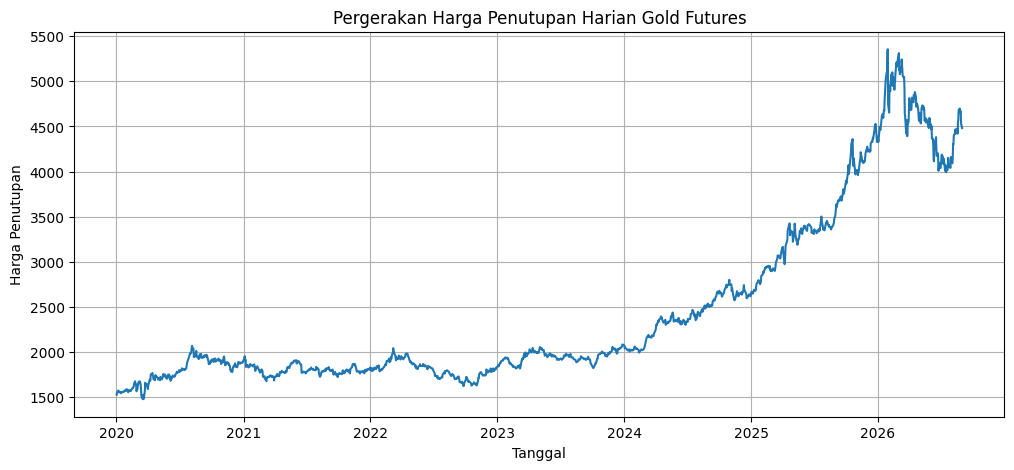

In [59]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12,5))

plt.plot(
    gold['Date'],
    gold['Close']
)

plt.title(
    'Pergerakan Harga Penutupan Harian Gold Futures'
)

plt.xlabel('Tanggal')
plt.ylabel('Harga Penutupan')

plt.grid(True)
plt.show()

In [ ]:
from statsmodels.tsa.seasonal import seasonal_decompose
import matplotlib.pyplot as plt

# Menggunakan data latih yang belum di-diff
# Ganti period=252 (asumsi 252 hari kerja/trading dalam setahun)
# atau period=30 (bulanan) untuk melihat siklusnya
dekomposisi = seasonal_decompose(train_data, model='additive', period=252)

fig = dekomposisi.plot()
fig.set_size_inches(14, 8)
plt.show()

##Split Data


Skema 1 (82% Train : 18% Test): total=1501, train=1230 (2020-01-02 s/d 2025-07-09), test=271 (2025-07-10 s/d 2026-08-31)
Skema 2 (87% Train : 13% Test): total=1501, train=1305 (2020-01-02 s/d 2025-11-18), test=196 (2025-11-19 s/d 2026-08-31)
Skema 3 (90% Train : 10% Test): total=1501, train=1350 (2020-01-02 s/d 2026-01-30), test=151 (2026-02-02 s/d 2026-08-31)


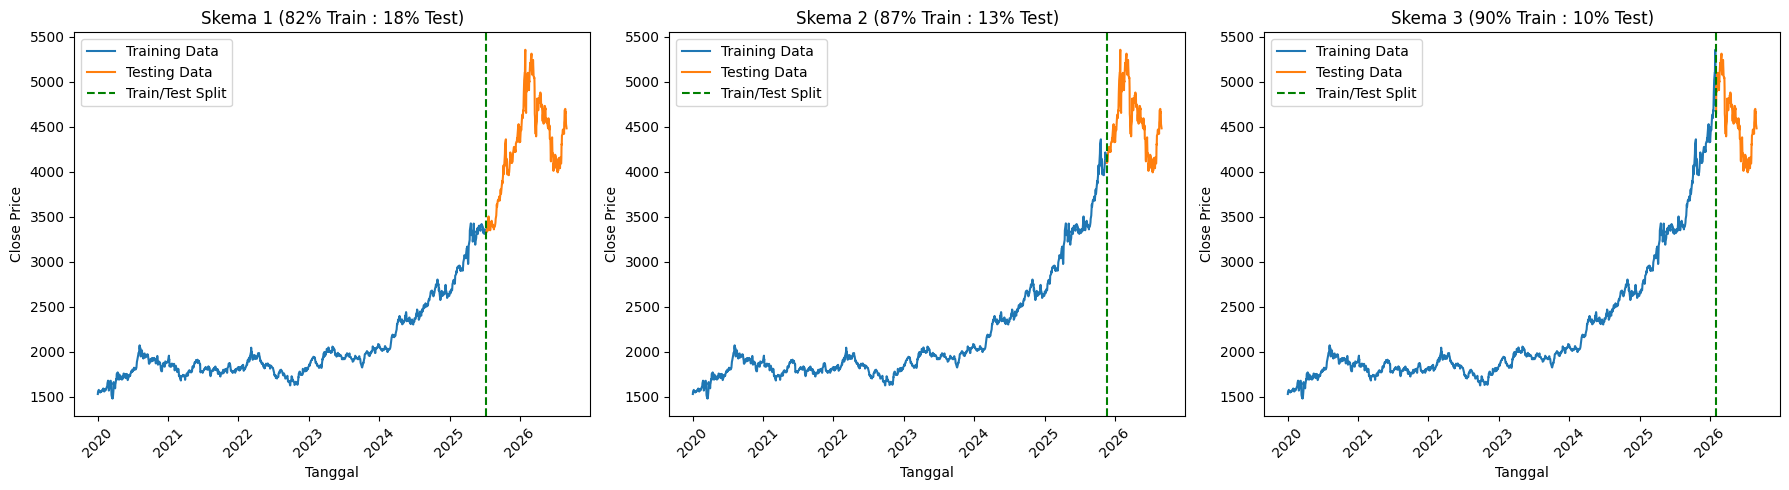

In [60]:
import pandas as pd
import matplotlib.pyplot as plt

# Pastikan 'Date' berformat datetime dan dijadikan index
df = gold.copy()
df['Date'] = pd.to_datetime(df['Date'])
df = df.set_index('Date').sort_index()

n = len(df)

# Variasikan rasio train/test pada SELURUH data hingga 2026
split_ratios = {
    "Skema 1 (82% Train : 18% Test)": 0.82,
    "Skema 2 (87% Train : 13% Test)": 0.87,
    "Skema 3 (90% Train : 10% Test)": 0.90
}

splits = {}

# Proses pembagian data berdasarkan seluruh dataset
for name, ratio in split_ratios.items():
    train_size = int(n * ratio)

    train = df.iloc[:train_size]
    test = df.iloc[train_size:]

    splits[name] = {"train": train, "test": test}

    print(f"{name}: total={n}, train={len(train)} "
          f"({train.index.min().date()} s/d {train.index.max().date()}), "
          f"test={len(test)} ({test.index.min().date()} s/d {test.index.max().date()})")

# Visualisasi grafik split data
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (name, sp) in zip(axes, splits.items()):
    ax.plot(sp["train"].index, sp["train"]["Close"], label="Training Data", color="tab:blue")
    ax.plot(sp["test"].index, sp["test"]["Close"], label="Testing Data", color="tab:orange")
    ax.axvline(sp["test"].index.min(), color="green", linestyle="--", label="Train/Test Split")

    ax.set_title(name)
    ax.set_xlabel("Tanggal")
    ax.set_ylabel("Close Price")
    ax.legend()
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

In [61]:
n_test = int(np.ceil(len(gold) * 0.10))

train = gold.iloc[:-n_test].copy()
test  = gold.iloc[-n_test:].copy()

print("Jumlah train :", len(train))
print("Jumlah test  :", len(test))

print(
    "Periode train :",
    train['Date'].min(),
    "-",
    train['Date'].max()
)

print(
    "Periode test :",
    test['Date'].min(),
    "-",
    test['Date'].max()
)

Jumlah train : 1350
Jumlah test  : 151
Periode train : 2020-01-02 00:00:00 - 2026-01-30 00:00:00
Periode test : 2026-02-02 00:00:00 - 2026-08-31 00:00:00


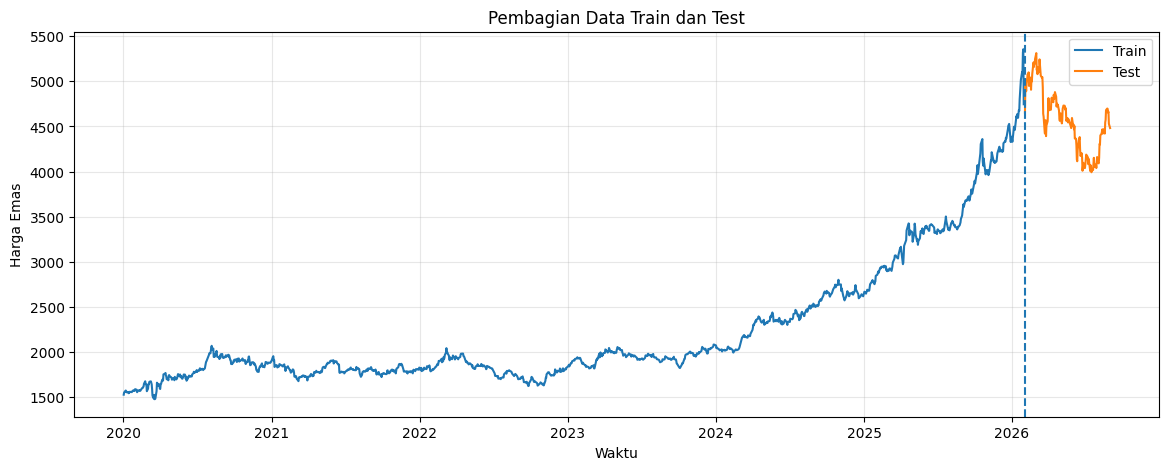

In [62]:
plt.figure(figsize=(14,5))

plt.plot(
    train['Date'],
    train['Close'],
    label='Train'
)

plt.plot(
    test['Date'],
    test['Close'],
    label='Test'
)

plt.axvline(
    test['Date'].iloc[0],
    linestyle='--'
)

plt.title('Pembagian Data Train dan Test')
plt.xlabel('Waktu')
plt.ylabel('Harga Emas')

plt.legend()
plt.grid(alpha=0.3)

plt.show()

tansformasi boxcox

In [63]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import boxcox, boxcox_llf
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

In [64]:
train_boxcox, lambda_fit, ci = boxcox(
    train['Close'],
    alpha=0.05
)

train['close_boxcox'] = train_boxcox

print("Lambda optimal :", lambda_fit)
print("95% CI         :", ci)

Lambda optimal : -3.008353093075329
95% CI         : (-3.252921946539268, -2.767436077199185)


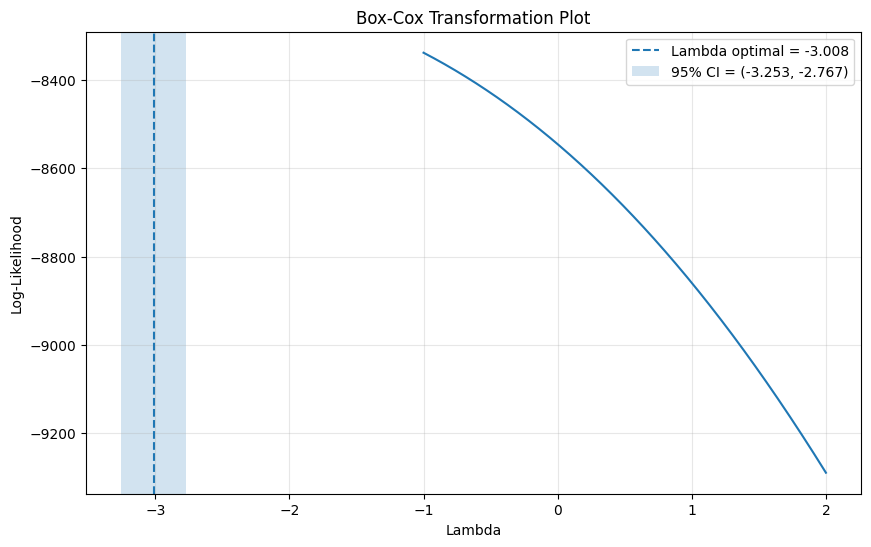

In [65]:
lambda_values = np.linspace(
    -1,
    2,
    500
)

log_likelihood = [
    boxcox_llf(lmbda, train['Close'])
    for lmbda in lambda_values
]

plt.figure(figsize=(10,6))

plt.plot(
    lambda_values,
    log_likelihood
)

plt.axvline(
    lambda_fit,
    linestyle='--',
    label=f'Lambda optimal = {lambda_fit:.3f}'
)

plt.axvspan(
    ci[0],
    ci[1],
    alpha=0.2,
    label=f'95% CI = ({ci[0]:.3f}, {ci[1]:.3f})'
)

plt.title('Box-Cox Transformation Plot')
plt.xlabel('Lambda')
plt.ylabel('Log-Likelihood')

plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [66]:
def uji_adf(data, nama='Data'):

    hasil = adfuller(
        data.dropna(),
        autolag='AIC'
    )

    print(nama)
    print("ADF Statistic :", hasil[0])
    print("p-value       :", hasil[1])

    if hasil[1] < 0.05:
        print("Kesimpulan    : Data stasioner")
    else:
        print("Kesimpulan    : Data tidak stasioner")

In [67]:
uji_adf(
    train['Close'],
    'Harga Emas Sebelum Transformasi'
)

Harga Emas Sebelum Transformasi
ADF Statistic : 4.267543720850615
p-value       : 1.0
Kesimpulan    : Data tidak stasioner


/tmp/ipykernel_4615/1405573020.py:3: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  hasil = adfuller(


In [68]:
train_boxcox, lambda_fit, ci = boxcox(
    train['Close'],
    alpha=0.05
)

train['close_boxcox'] = train_boxcox

print("Lambda optimal :", lambda_fit)
print("95% CI         :", ci)

Lambda optimal : -3.008353093075329
95% CI         : (-3.252921946539268, -2.767436077199185)


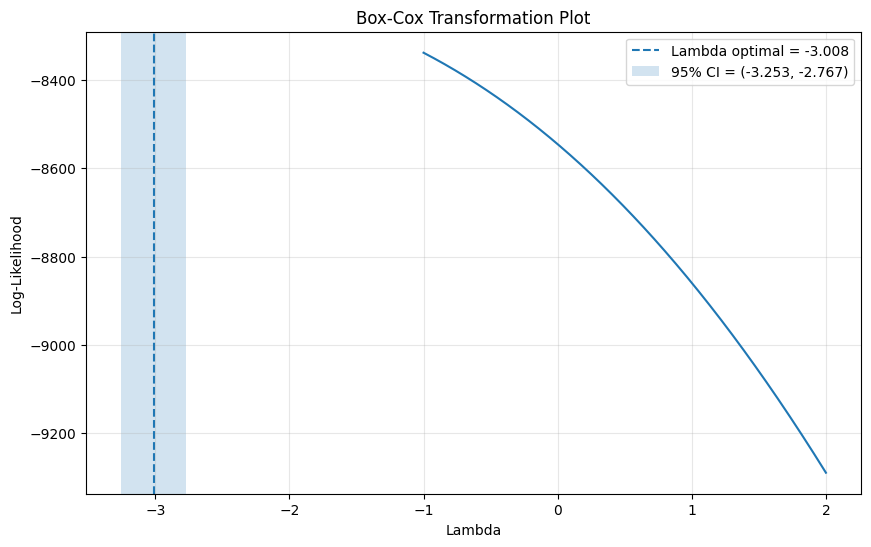

In [69]:
lambda_values = np.linspace(
    -1,
    2,
    500
)

log_likelihood = [
    boxcox_llf(lmbda, train['Close'])
    for lmbda in lambda_values
]

plt.figure(figsize=(10,6))

plt.plot(
    lambda_values,
    log_likelihood
)

plt.axvline(
    lambda_fit,
    linestyle='--',
    label=f'Lambda optimal = {lambda_fit:.3f}'
)

plt.axvspan(
    ci[0],
    ci[1],
    alpha=0.2,
    label=f'95% CI = ({ci[0]:.3f}, {ci[1]:.3f})'
)

plt.title('Box-Cox Transformation Plot')
plt.xlabel('Lambda')
plt.ylabel('Log-Likelihood')

plt.legend()
plt.grid(alpha=0.3)

plt.show()

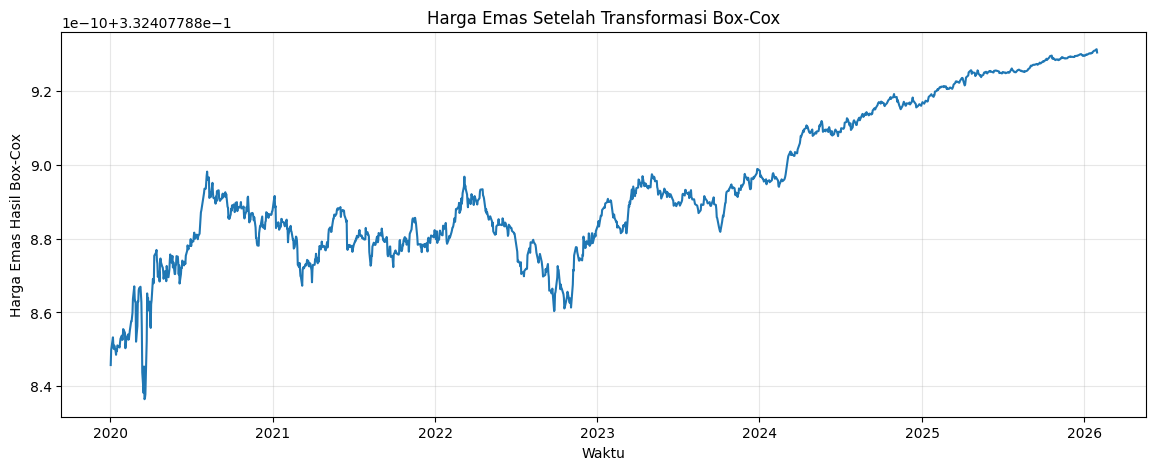

In [70]:
plt.figure(figsize=(14,5))

plt.plot(
    train['Date'],
    train['close_boxcox']
)

plt.title('Harga Emas Setelah Transformasi Box-Cox')
plt.xlabel('Waktu')
plt.ylabel('Harga Emas Hasil Box-Cox')

plt.grid(alpha=0.3)
plt.show()

In [71]:
uji_adf(
    train['close_boxcox'],
    'Harga Emas Setelah Box-Cox'
)

Harga Emas Setelah Box-Cox
ADF Statistic : -1.143238748829796
p-value       : 0.6975245531659413
Kesimpulan    : Data tidak stasioner


/tmp/ipykernel_4615/1405573020.py:3: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  hasil = adfuller(


In [72]:
train['diff1'] = (
    train['close_boxcox']
    .diff()
)

In [73]:
data_stationer = (
    train['diff1']
    .dropna()
)

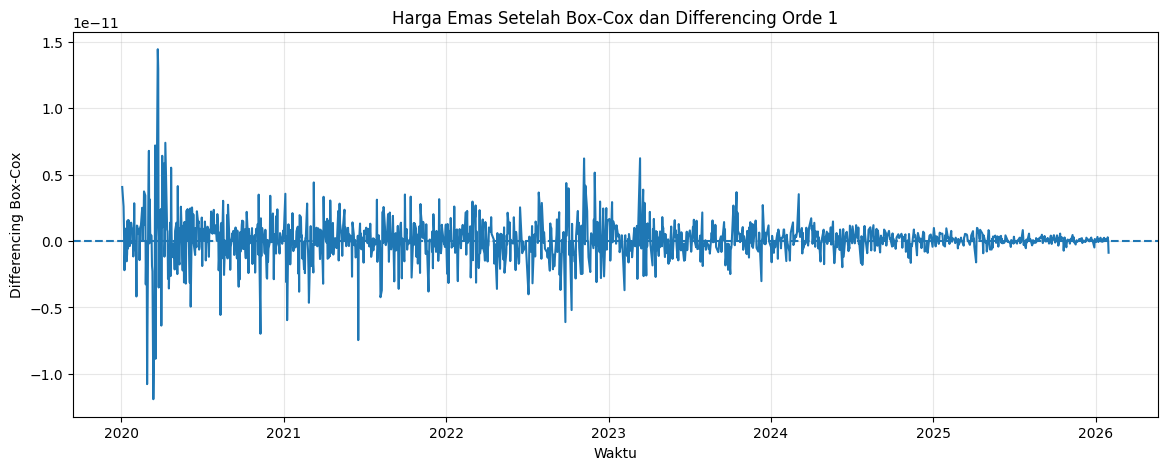

In [74]:
plt.figure(figsize=(14,5))

plt.plot(
    train.loc[data_stationer.index, 'Date'],
    data_stationer
)

plt.axhline(
    y=0,
    linestyle='--'
)

plt.title(
    'Harga Emas Setelah Box-Cox dan Differencing Orde 1'
)

plt.xlabel('Waktu')
plt.ylabel('Differencing Box-Cox')

plt.grid(alpha=0.3)
plt.show()

In [75]:
uji_adf(
    data_stationer,
    'Box-Cox + Differencing Orde 1'
)

Box-Cox + Differencing Orde 1
ADF Statistic : -10.539725071900218
p-value       : 8.713165280422649e-19
Kesimpulan    : Data stasioner


/tmp/ipykernel_4615/1405573020.py:3: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  hasil = adfuller(


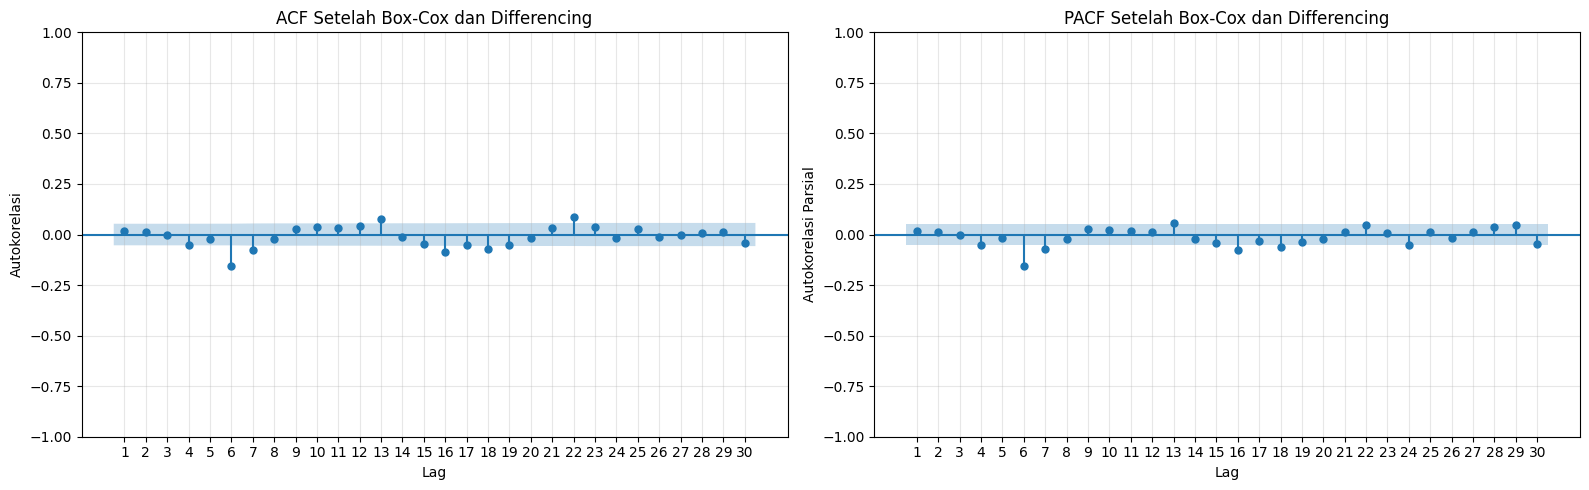

In [76]:
maks_lag = 30

fig, ax = plt.subplots(
    1, 2,
    figsize=(16,5)
)

# ACF
plot_acf(
    data_stationer,
    lags=maks_lag,
    alpha=0.05,
    zero=False,
    ax=ax[0]
)

ax[0].set_title(
    'ACF Setelah Box-Cox dan Differencing'
)

ax[0].set_xlabel('Lag')
ax[0].set_ylabel('Autokorelasi')

ax[0].set_xticks(
    range(1, maks_lag + 1)
)

ax[0].grid(alpha=0.3)


# PACF
plot_pacf(
    data_stationer,
    lags=maks_lag,
    alpha=0.05,
    zero=False,
    method='ywm',
    ax=ax[1]
)

ax[1].set_title(
    'PACF Setelah Box-Cox dan Differencing'
)

ax[1].set_xlabel('Lag')
ax[1].set_ylabel('Autokorelasi Parsial')

ax[1].set_xticks(
    range(1, maks_lag + 1)
)

ax[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

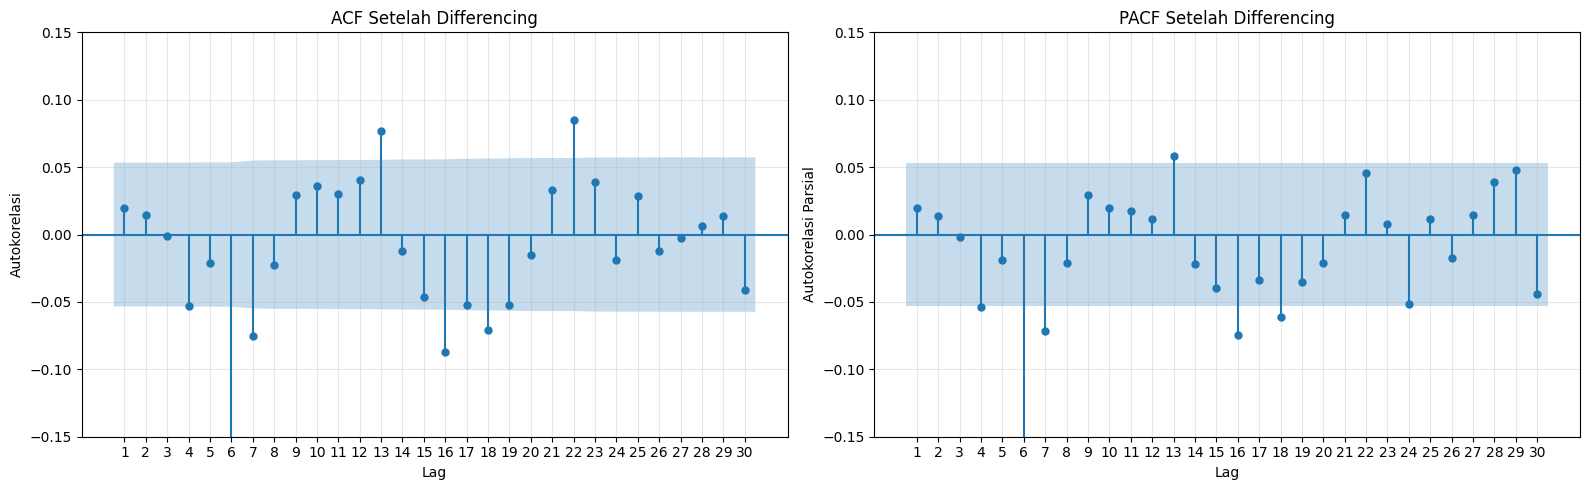

In [77]:
maks_lag = 30

fig, ax = plt.subplots(
    1, 2,
    figsize=(16,5)
)

plot_acf(
    data_stationer,
    lags=maks_lag,
    alpha=0.05,
    zero=False,
    ax=ax[0]
)

ax[0].set_title('ACF Setelah Differencing')
ax[0].set_xlabel('Lag')
ax[0].set_ylabel('Autokorelasi')
ax[0].set_xticks(range(1, maks_lag + 1))

# Zoom
ax[0].set_ylim(-0.15, 0.15)

ax[0].grid(alpha=0.3)


plot_pacf(
    data_stationer,
    lags=maks_lag,
    alpha=0.05,
    zero=False,
    method='ywm',
    ax=ax[1]
)

ax[1].set_title('PACF Setelah Differencing')
ax[1].set_xlabel('Lag')
ax[1].set_ylabel('Autokorelasi Parsial')
ax[1].set_xticks(range(1, maks_lag + 1))

# Zoom
ax[1].set_ylim(-0.15, 0.15)

ax[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

Transformasi log

In [78]:
train['log_close'] = np.log(
    train['Close']
)

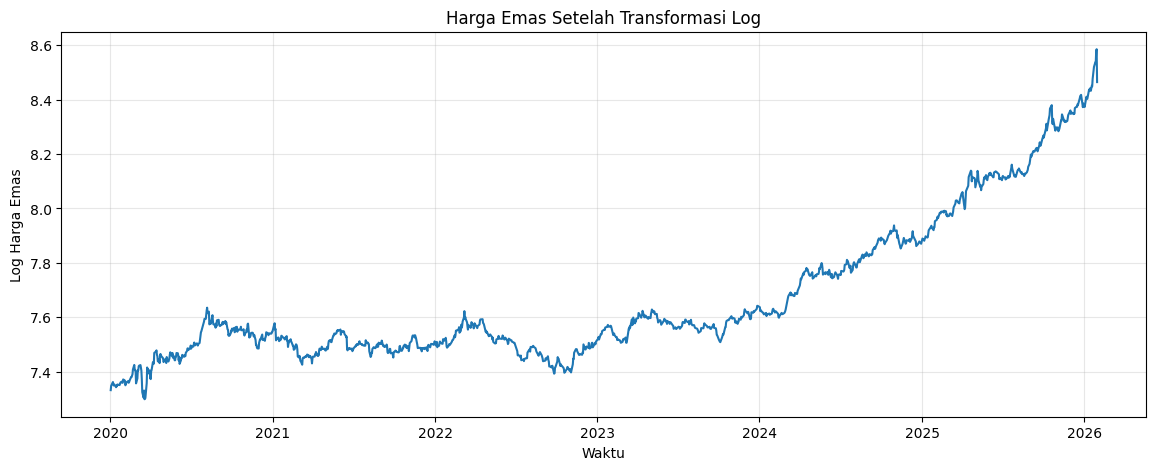

In [79]:
plt.figure(figsize=(14,5))

plt.plot(
    train['Date'],
    train['log_close']
)

plt.title('Harga Emas Setelah Transformasi Log')
plt.xlabel('Waktu')
plt.ylabel('Log Harga Emas')

plt.grid(alpha=0.3)
plt.show()

adf sebelum dif


In [80]:
def uji_adf(data, nama='Data'):

    hasil = adfuller(
        data.dropna(),
        autolag='AIC'
    )

    print(nama)
    print('ADF Statistic :', hasil[0])
    print('p-value       :', hasil[1])

    if hasil[1] < 0.05:
        print('Kesimpulan    : Data stasioner')
    else:
        print('Kesimpulan    : Data tidak stasioner')

In [81]:
uji_adf(
    train['log_close'],
    'Log Harga Emas'
)

Log Harga Emas
ADF Statistic : 2.434423179284501
p-value       : 0.9990255996134092
Kesimpulan    : Data tidak stasioner


/tmp/ipykernel_4615/3757873671.py:3: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  hasil = adfuller(


diff orde 1


In [82]:
train['log_diff1'] = (
    train['log_close']
    .diff()
)

In [83]:
data_stationer = (
    train['log_diff1']
    .dropna()
)

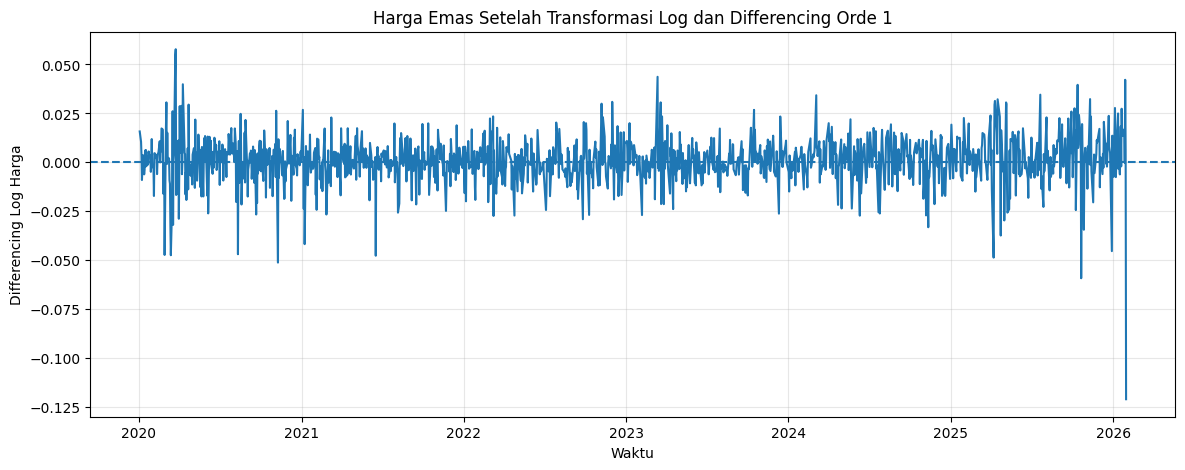

In [84]:
plt.figure(figsize=(14,5))

plt.plot(
    train['Date'].iloc[1:],
    data_stationer
)

plt.axhline(
    y=0,
    linestyle='--'
)

plt.title(
    'Harga Emas Setelah Transformasi Log dan Differencing Orde 1'
)

plt.xlabel('Waktu')
plt.ylabel('Differencing Log Harga')

plt.grid(alpha=0.3)

plt.show()

adf setelah diff

In [85]:
uji_adf(
    data_stationer,
    'Log Harga Emas Setelah Differencing Orde 1'
)

Log Harga Emas Setelah Differencing Orde 1
ADF Statistic : -16.770676377380383
p-value       : 1.2877071242534023e-29
Kesimpulan    : Data stasioner


/tmp/ipykernel_4615/3757873671.py:3: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  hasil = adfuller(


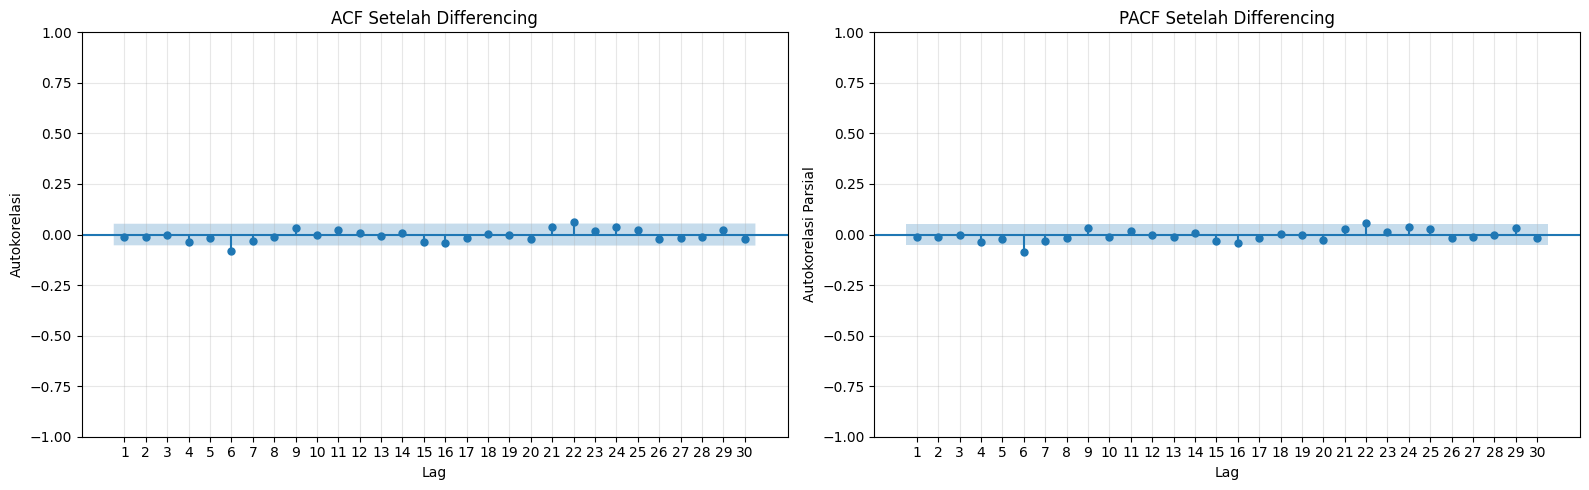

In [86]:
maks_lag = 30

fig, ax = plt.subplots(
    1, 2,
    figsize=(16,5)
)

# ACF
plot_acf(
    data_stationer,
    lags=maks_lag,
    alpha=0.05,
    zero=False,
    ax=ax[0]
)

ax[0].set_title(
    'ACF Setelah Differencing'
)

ax[0].set_xlabel('Lag')
ax[0].set_ylabel('Autokorelasi')

ax[0].set_xticks(
    range(1, maks_lag + 1)
)

ax[0].grid(alpha=0.3)


# PACF
plot_pacf(
    data_stationer,
    lags=maks_lag,
    alpha=0.05,
    zero=False,
    method='ywm',
    ax=ax[1]
)

ax[1].set_title(
    'PACF Setelah Differencing'
)

ax[1].set_xlabel('Lag')
ax[1].set_ylabel(
    'Autokorelasi Parsial'
)

ax[1].set_xticks(
    range(1, maks_lag + 1)
)

ax[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

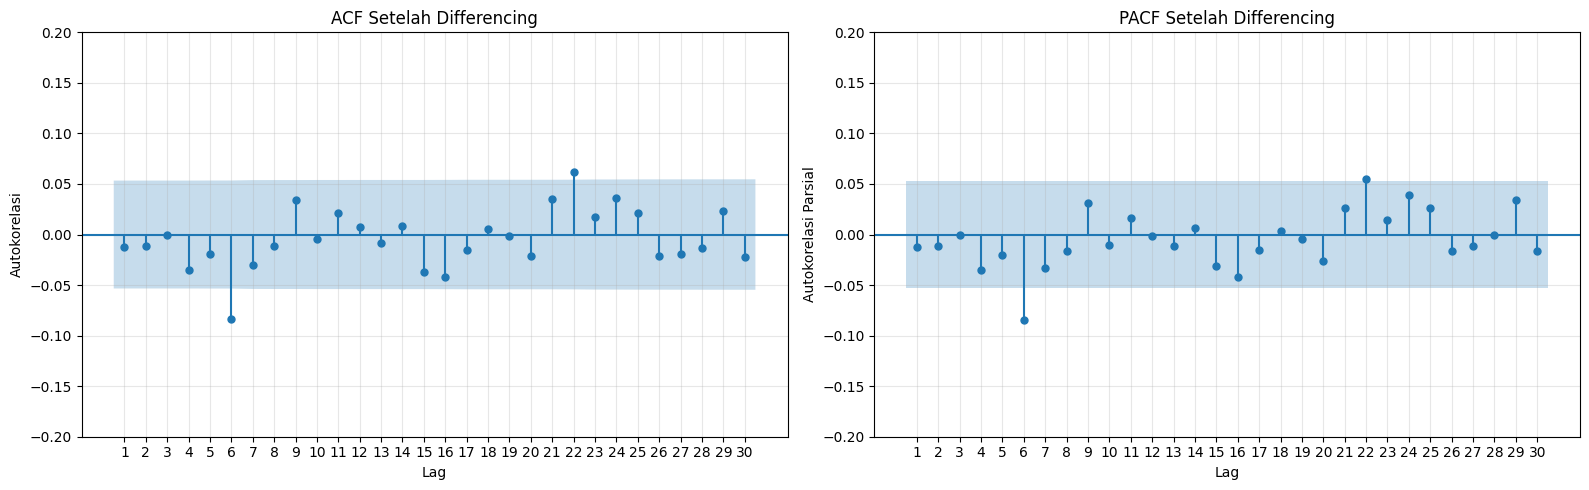

In [87]:
maks_lag = 30

fig, ax = plt.subplots(
    1, 2,
    figsize=(16,5)
)

plot_acf(
    data_stationer,
    lags=maks_lag,
    alpha=0.05,
    zero=False,
    ax=ax[0]
)

ax[0].set_title(
    'ACF Setelah Differencing'
)

ax[0].set_xlabel('Lag')
ax[0].set_ylabel('Autokorelasi')

ax[0].set_xticks(
    range(1, maks_lag + 1)
)

ax[0].set_ylim(-0.20, 0.20)

ax[0].grid(alpha=0.3)


plot_pacf(
    data_stationer,
    lags=maks_lag,
    alpha=0.05,
    zero=False,
    method='ywm',
    ax=ax[1]
)

ax[1].set_title(
    'PACF Setelah Differencing'
)

ax[1].set_xlabel('Lag')
ax[1].set_ylabel(
    'Autokorelasi Parsial'
)

ax[1].set_xticks(
    range(1, maks_lag + 1)
)

ax[1].set_ylim(-0.20, 0.20)

ax[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

##Persiapan

In [88]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import boxcox
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

In [89]:
def uji_adf(data, nama='Data'):

    data = pd.Series(data).dropna()

    hasil = adfuller(
        data,
        autolag='AIC'
    )

    print("=" * 60)
    print(nama)
    print("ADF Statistic :", hasil[0])
    print("p-value       :", hasil[1])

    if hasil[1] < 0.05:
        print("Kesimpulan    : STASIONER")
    else:
        print("Kesimpulan    : TIDAK STASIONER")

    print("=" * 60)

In [90]:
def plot_acf_pacf(data, judul, lags=30):

    data = pd.Series(data).dropna()

    fig, ax = plt.subplots(
        1, 2,
        figsize=(16,5)
    )

    plot_acf(
        data,
        lags=lags,
        zero=False,
        alpha=0.05,
        ax=ax[0]
    )

    ax[0].set_title(f'ACF {judul}')
    ax[0].set_xlabel('Lag')
    ax[0].set_ylabel('Autokorelasi')
    ax[0].grid(alpha=0.3)

    plot_pacf(
        data,
        lags=lags,
        zero=False,
        alpha=0.05,
        method='ywm',
        ax=ax[1]
    )

    ax[1].set_title(f'PACF {judul}')
    ax[1].set_xlabel('Lag')
    ax[1].set_ylabel('Autokorelasi Parsial')
    ax[1].grid(alpha=0.3)

    plt.tight_layout()
    plt.show()

##SKENARIO 1

In [91]:
data_skenario1 = train['Close'].copy()

uji_adf(
    data_skenario1,
    'Skenario 1: Data Asli'
)

Skenario 1: Data Asli
ADF Statistic : 4.267543720850615
p-value       : 1.0
Kesimpulan    : TIDAK STASIONER


/tmp/ipykernel_4615/614846475.py:5: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  hasil = adfuller(


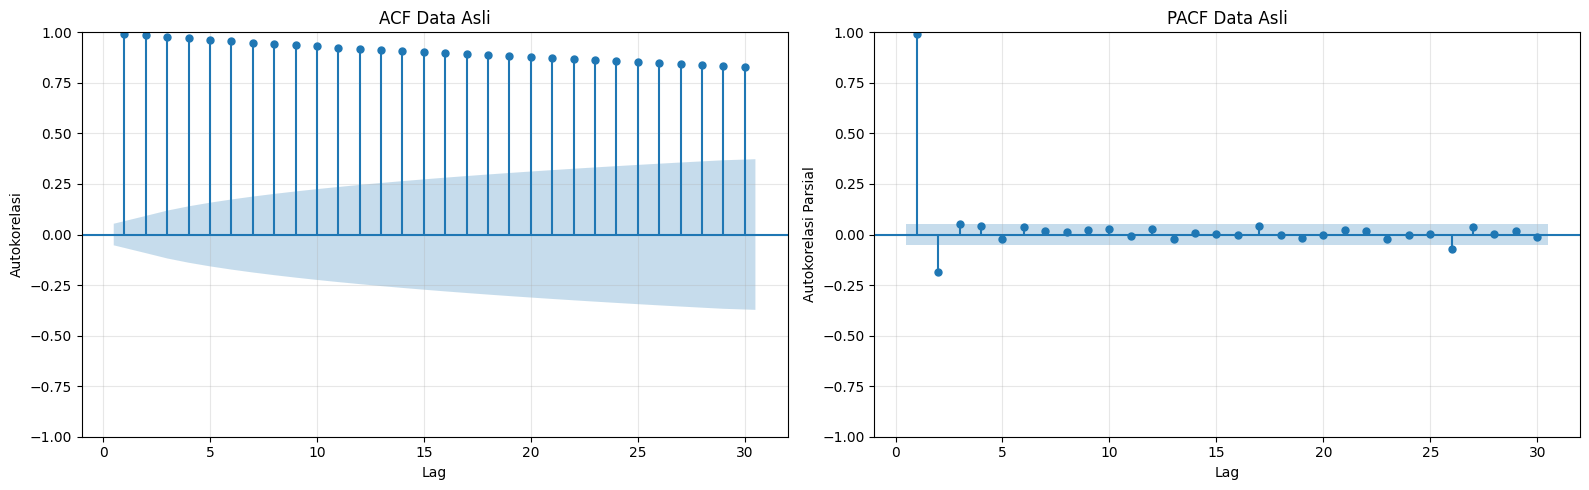

In [92]:
plot_acf_pacf(
    data_skenario1,
    'Data Asli'
)

##skenario 2 box cox tanpa diff

In [93]:
boxcox_train, lambda_boxcox, ci = boxcox(
    train['Close'],
    alpha=0.05
)

data_skenario2 = pd.Series(
    boxcox_train,
    index=train.index
)

print("Lambda Box-Cox :", lambda_boxcox)
print("95% CI          :", ci)

Lambda Box-Cox : -3.008353093075329
95% CI          : (-3.252921946539268, -2.767436077199185)


In [94]:
uji_adf(
    data_skenario2,
    'Skenario 2: Box-Cox Tanpa Differencing'
)

Skenario 2: Box-Cox Tanpa Differencing
ADF Statistic : -1.143238748829796
p-value       : 0.6975245531659413
Kesimpulan    : TIDAK STASIONER


/tmp/ipykernel_4615/614846475.py:5: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  hasil = adfuller(


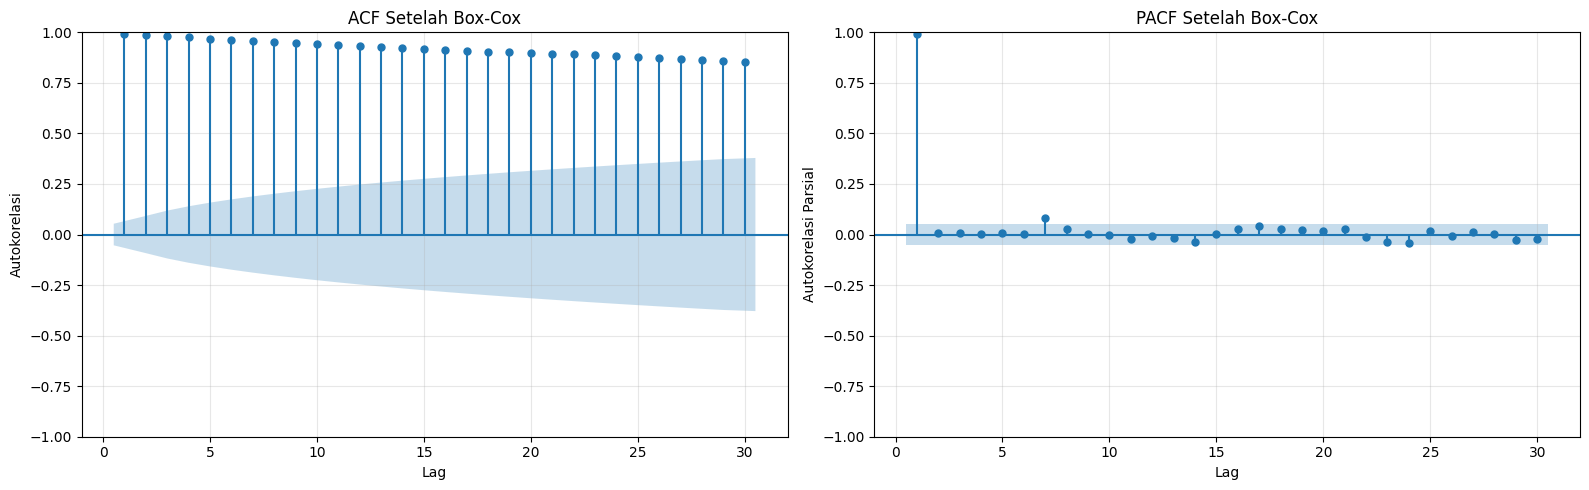

In [95]:
plot_acf_pacf(
    data_skenario2,
    'Setelah Box-Cox'
)

##skenario 3 diff tanpa boc cox

In [96]:
data_skenario3 = (
    train['Close']
    .diff()
    .dropna()
)

In [97]:
uji_adf(
    data_skenario3,
    'Skenario 3: Differencing Tanpa Box-Cox'
)

Skenario 3: Differencing Tanpa Box-Cox
ADF Statistic : -5.538736463825978
p-value       : 1.7208777657289553e-06
Kesimpulan    : STASIONER


/tmp/ipykernel_4615/614846475.py:5: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  hasil = adfuller(


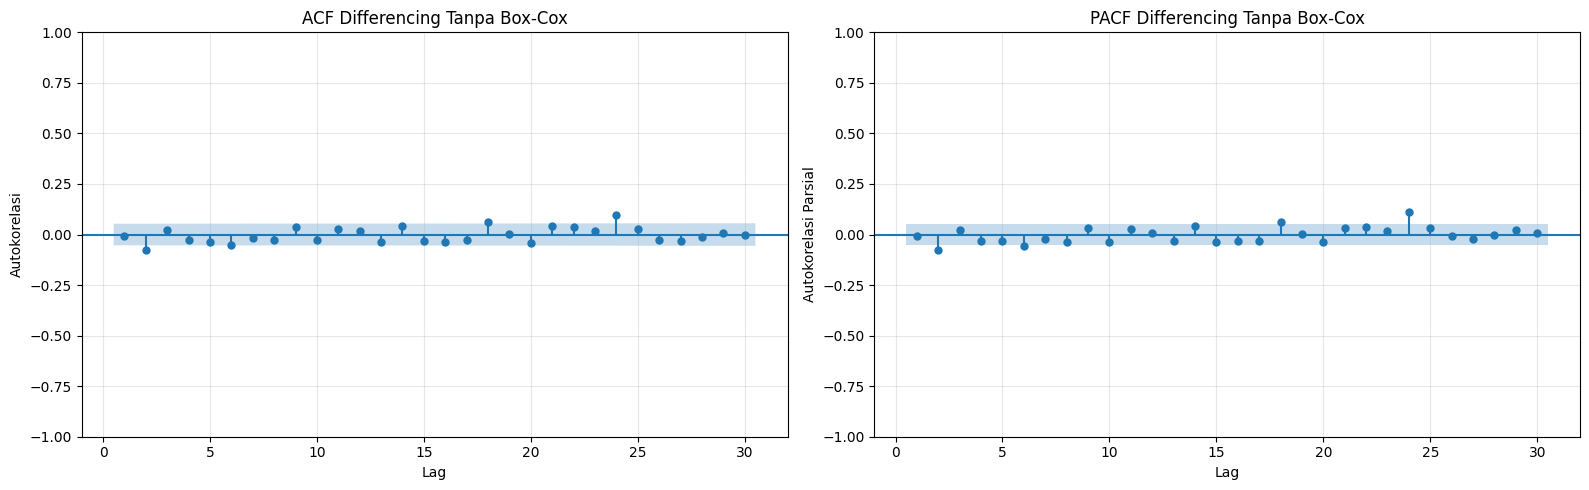

In [98]:
plot_acf_pacf(
    data_skenario3,
    'Differencing Tanpa Box-Cox'
)

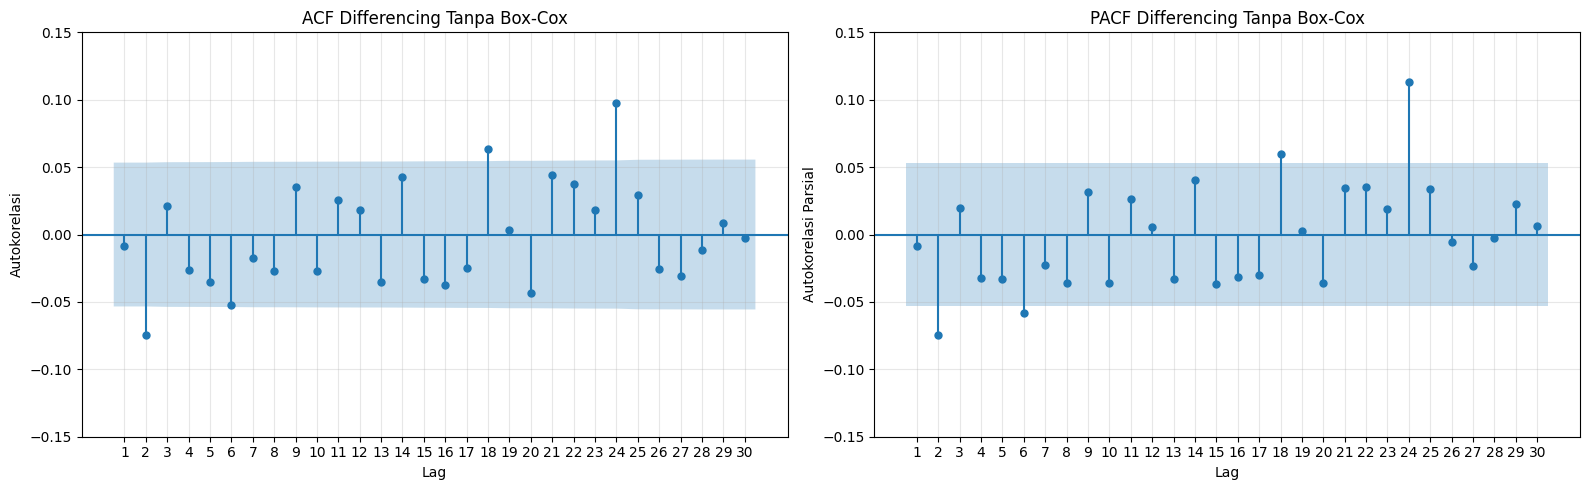

In [99]:
maks_lag = 30

fig, ax = plt.subplots(1, 2, figsize=(16,5))

plot_acf(
    data_skenario3,
    lags=maks_lag,
    alpha=0.05,
    zero=False,
    ax=ax[0]
)

ax[0].set_title('ACF Differencing Tanpa Box-Cox')
ax[0].set_xlabel('Lag')
ax[0].set_ylabel('Autokorelasi')
ax[0].set_xticks(range(1, maks_lag + 1))
ax[0].set_ylim(-0.15, 0.15)
ax[0].grid(alpha=0.3)


plot_pacf(
    data_skenario3,
    lags=maks_lag,
    alpha=0.05,
    zero=False,
    method='ywm',
    ax=ax[1]
)

ax[1].set_title('PACF Differencing Tanpa Box-Cox')
ax[1].set_xlabel('Lag')
ax[1].set_ylabel('Autokorelasi Parsial')
ax[1].set_xticks(range(1, maks_lag + 1))
ax[1].set_ylim(-0.15, 0.15)
ax[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

##Skenario 4 box cox+diff

In [100]:
train['close_boxcox'] = boxcox_train

In [101]:
train['diff_boxcox'] = (
    train['close_boxcox']
    .diff()
)

data_skenario4 = (
    train['diff_boxcox']
    .dropna()
)

In [102]:
train['diff_boxcox'] = (
    train['close_boxcox']
    .diff()
)

data_skenario4 = (
    train['diff_boxcox']
    .dropna()
)

In [103]:
uji_adf(
    data_skenario4,
    'Skenario 4: Box-Cox + Differencing'
)

Skenario 4: Box-Cox + Differencing
ADF Statistic : -10.539725071900218
p-value       : 8.713165280422649e-19
Kesimpulan    : STASIONER


/tmp/ipykernel_4615/614846475.py:5: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  hasil = adfuller(


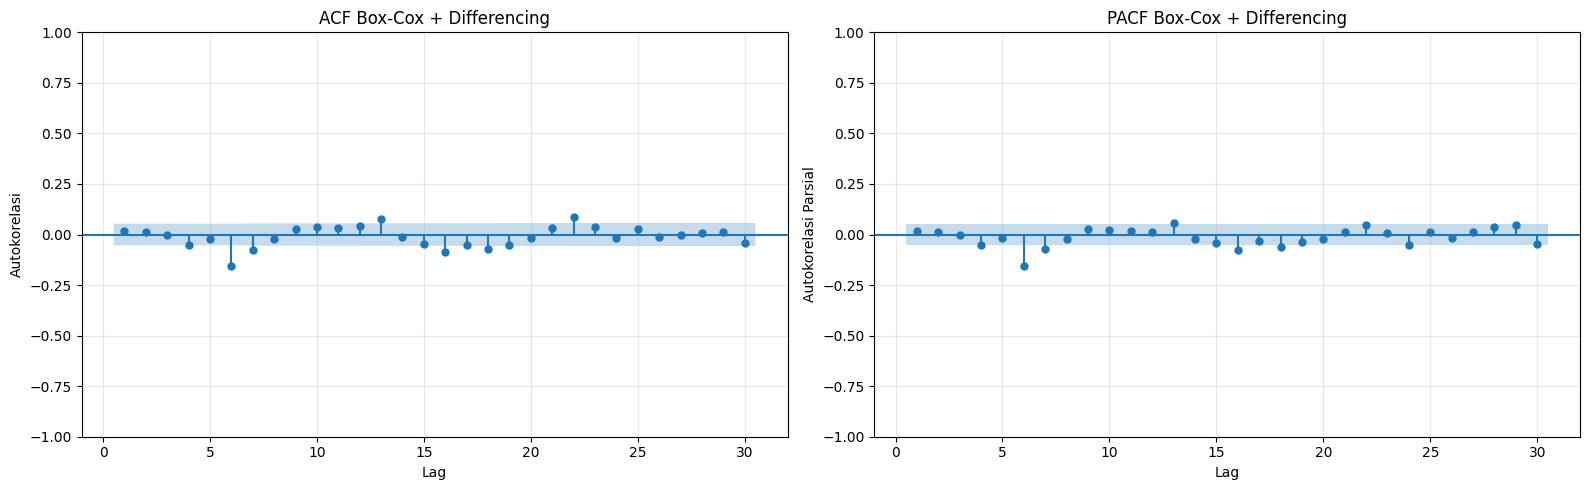

In [104]:
plot_acf_pacf(
    data_skenario4,
    'Box-Cox + Differencing'
)

In [105]:
def ambil_adf(data):

    hasil = adfuller(
        pd.Series(data).dropna(),
        autolag='AIC'
    )

    return hasil[0], hasil[1]


hasil_skenario = []

skenario = {
    'Data Asli':
        data_skenario1,

    'Box-Cox':
        data_skenario2,

    'Differencing':
        data_skenario3,

    'Box-Cox + Differencing':
        data_skenario4
}


for nama, data in skenario.items():

    adf_stat, pvalue = ambil_adf(data)

    hasil_skenario.append({
        'Skenario': nama,
        'ADF Statistic': adf_stat,
        'p-value': pvalue,
        'Stasioner':
            'Ya'
            if pvalue < 0.05
            else 'Tidak'
    })


tabel_adf = pd.DataFrame(
    hasil_skenario
)

tabel_adf

/tmp/ipykernel_4615/35911643.py:3: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  hasil = adfuller(
/tmp/ipykernel_4615/35911643.py:3: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  hasil = adfuller(
/tmp/ipykernel_4615/35911643.py:3: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after Jul

,Skenario,ADF Statistic,p-value,Stasioner
0,Data Asli,4.267544,1.000000e+00,Tidak
1,Box-Cox,-1.143239,6.975246e-01,Tidak
2,Differencing,-5.538736,1.720878e-06,Ya
3,Box-Cox + Differencing,-10.539725,8.713165e-19,Ya


## Kandidat model awal


In [106]:
from statsmodels.tsa.arima.model import ARIMA
import warnings

In [107]:
with warnings.catch_warnings():
    warnings.simplefilter("ignore")

    model_210 = ARIMA(
        train['Close'],
        order=(2,1,0)
    ).fit()

    model_012 = ARIMA(
        train['Close'],
        order=(0,1,2)
    ).fit()

    model_212 = ARIMA(
        train['Close'],
        order=(2,1,2)
    ).fit()

In [108]:
print(model_210.summary())

                               SARIMAX Results                                
Dep. Variable:                  Close   No. Observations:                 1350
Model:                 ARIMA(2, 1, 0)   Log Likelihood               -6664.312
Date:                Fri, 16 Oct 2026   AIC                          13334.624
Time:                        03:52:09   BIC                          13350.245
Sample:                             0   HQIC                         13340.474
                               - 1350                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.0024      0.024     -0.098      0.922      -0.050       0.045
ar.L2         -0.0902      0.016     -5.697      0.000      -0.121      -0.059
sigma2      1145.2829     14.399     79.537      0.0

In [109]:
print(model_012.summary())

                               SARIMAX Results                                
Dep. Variable:                  Close   No. Observations:                 1350
Model:                 ARIMA(0, 1, 2)   Log Likelihood               -6664.066
Date:                Fri, 16 Oct 2026   AIC                          13334.132
Time:                        03:52:09   BIC                          13349.754
Sample:                             0   HQIC                         13339.983
                               - 1350                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ma.L1          0.0036      0.024      0.151      0.880      -0.043       0.050
ma.L2         -0.0952      0.015     -6.545      0.000      -0.124      -0.067
sigma2      1143.8040     14.191     80.603      0.0

In [110]:
print(model_212.summary())

                               SARIMAX Results                                
Dep. Variable:                  Close   No. Observations:                 1350
Model:                 ARIMA(2, 1, 2)   Log Likelihood               -6662.585
Date:                Fri, 16 Oct 2026   AIC                          13335.171
Time:                        03:52:09   BIC                          13361.206
Sample:                             0   HQIC                         13344.922
                               - 1350                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.0270      0.155     -0.174      0.862      -0.330       0.276
ar.L2          0.4703      0.159      2.954      0.003       0.158       0.782
ma.L1          0.0330      0.138      0.239      0.8

##Perbandingan AIC dan BIC

In [111]:
hasil_awal = pd.DataFrame({
    'Model': [
        'ARIMA(2,1,0)',
        'ARIMA(0,1,2)',
        'ARIMA(2,1,2)'
    ],

    'AIC': [
        model_210.aic,
        model_012.aic,
        model_212.aic
    ],

    'BIC': [
        model_210.bic,
        model_012.bic,
        model_212.bic
    ]
})

hasil_awal.round(4)

,Model,AIC,BIC
0,"ARIMA(2,1,0)",13334.6240,13350.2454
1,"ARIMA(0,1,2)",13334.1323,13349.7536
2,"ARIMA(2,1,2)",13335.1709,13361.2065


##Cek signifikansi parameter

In [112]:
models_awal = {
    (2,1,0): model_210,
    (0,1,2): model_012,
    (2,1,2): model_212
}

hasil_parameter = []

for order, model in models_awal.items():

    for parameter, coef, pvalue in zip(
        model.params.index,
        model.params.values,
        model.pvalues.values
    ):

        if parameter != 'sigma2':

            hasil_parameter.append({
                'Model': f'ARIMA{order}',
                'Parameter': parameter,
                'Koefisien': coef,
                'p-value': pvalue,
                'Keputusan':
                    'Signifikan'
                    if pvalue < 0.05
                    else 'Tidak Signifikan'
            })

tabel_parameter = pd.DataFrame(
    hasil_parameter
)

tabel_parameter.round(4)

,Model,Parameter,Koefisien,p-value,Keputusan
0,"ARIMA(2, 1, 0)",ar.L1,-0.0024,0.9216,Tidak Signifikan
1,"ARIMA(2, 1, 0)",ar.L2,-0.0902,0.0000,Signifikan
2,"ARIMA(0, 1, 2)",ma.L1,0.0036,0.8798,Tidak Signifikan
3,"ARIMA(0, 1, 2)",ma.L2,-0.0952,0.0000,Signifikan
4,"ARIMA(2, 1, 2)",ar.L1,-0.0270,0.8616,Tidak Signifikan
5,"ARIMA(2, 1, 2)",ar.L2,0.4703,0.0031,Signifikan
6,"ARIMA(2, 1, 2)",ma.L1,0.0330,0.8109,Tidak Signifikan
7,"ARIMA(2, 1, 2)",ma.L2,-0.5583,0.0001,Signifikan


##Overfitting

In [113]:
kandidat = [
    (2,1,0),
    (0,1,2),
    (2,1,2),

    # overfitting
    (3,1,0),
    (2,1,1),

    (0,1,3),
    (1,1,2),

    (3,1,2),
    (2,1,3)
]

In [114]:
models = {}

for order in kandidat:

    try:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")

            model = ARIMA(
                train['Close'],
                order=order
            ).fit()

        models[order] = model

    except Exception as e:
        print(
            f"ARIMA{order} gagal: {e}"
        )

##AIC, BIC + MAE, RMSE, MAPE

In [115]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error
)

In [116]:
hasil_model = []

actual = test['Close'].values

for order, model in models.items():

    # forecast sebanyak data test
    prediksi = model.forecast(
        steps=len(test)
    )

    # MAE
    mae = mean_absolute_error(
        actual,
        prediksi
    )

    # RMSE
    rmse = np.sqrt(
        mean_squared_error(
            actual,
            prediksi
        )
    )

    # MAPE
    mape = np.mean(
        np.abs(
            (actual - prediksi)
            / actual
        )
    ) * 100

    # Konvergensi
    converged = model.mle_retvals.get(
        'converged',
        True
    )

    hasil_model.append({
        'Model': f'ARIMA{order}',
        'AIC': model.aic,
        'BIC': model.bic,
        'MAE': mae,
        'RMSE': rmse,
        'MAPE (%)': mape,
        'Konvergen': converged
    })

In [117]:
tabel_model = pd.DataFrame(
    hasil_model
)

tabel_model.round(4)

,Model,AIC,BIC,MAE,RMSE,MAPE (%),Konvergen
0,"ARIMA(2, 1, 0)",13334.6240,13350.2454,345.0743,414.9922,7.8796,True
1,"ARIMA(0, 1, 2)",13334.1323,13349.7536,345.9400,415.9522,7.9005,True
2,"ARIMA(2, 1, 2)",13335.1709,13361.2065,349.0313,419.0254,7.9733,True
3,"ARIMA(3, 1, 0)",13335.2684,13356.0968,340.3563,409.7306,7.7646,True
4,"ARIMA(2, 1, 1)",13334.8219,13355.6503,340.9507,410.3435,7.7788,True
5,"ARIMA(0, 1, 3)",13335.1613,13355.9898,341.3975,410.8974,7.7900,True
6,"ARIMA(1, 1, 2)",13334.5839,13355.4124,341.8245,411.3079,7.8001,True
7,"ARIMA(3, 1, 2)",13336.9186,13368.1613,348.6042,418.5277,7.9628,True
8,"ARIMA(2, 1, 3)",13336.9238,13368.1665,348.6115,418.5404,7.9630,True


In [118]:
#Urutkan berdasarkan AIC
tabel_model.sort_values(
    'AIC'
).reset_index(drop=True)

,Model,AIC,BIC,MAE,RMSE,MAPE (%),Konvergen
0,"ARIMA(0, 1, 2)",13334.132293,13349.753649,345.940004,415.952168,7.900544,True
1,"ARIMA(1, 1, 2)",13334.583927,13355.412402,341.824503,411.307922,7.800079,True
2,"ARIMA(2, 1, 0)",13334.624017,13350.245373,345.074264,414.992212,7.879578,True
3,"ARIMA(2, 1, 1)",13334.821859,13355.650334,340.950695,410.343487,7.778786,True
4,"ARIMA(0, 1, 3)",13335.161344,13355.989819,341.397511,410.897436,7.789984,True
5,"ARIMA(2, 1, 2)",13335.170875,13361.206469,349.031296,419.025427,7.973266,True
6,"ARIMA(3, 1, 0)",13335.268366,13356.096842,340.356343,409.730598,7.764551,True
7,"ARIMA(3, 1, 2)",13336.918570,13368.161283,348.604175,418.527676,7.962817,True
8,"ARIMA(2, 1, 3)",13336.923807,13368.166521,348.611538,418.540395,7.963020,True


##Diagnostik residual

In [119]:
from statsmodels.stats.diagnostic import acorr_ljungbox

In [120]:
hasil_ljungbox = []

for order, model in models.items():

    resid = model.resid.dropna()

    lb = acorr_ljungbox(
        resid,
        lags=[10, 20],
        return_df=True
    )

    hasil_ljungbox.append({
        'Model': f'ARIMA{order}',
        'p-value LB lag 10':
            lb.loc[10, 'lb_pvalue'],

        'p-value LB lag 20':
            lb.loc[20, 'lb_pvalue']
    })


tabel_ljungbox = pd.DataFrame(
    hasil_ljungbox
)

tabel_ljungbox.round(4)

,Model,p-value LB lag 10,p-value LB lag 20
0,"ARIMA(2, 1, 0)",0.9859,0.9998
1,"ARIMA(0, 1, 2)",0.9890,0.9999
2,"ARIMA(2, 1, 2)",0.9987,1.0000
3,"ARIMA(3, 1, 0)",0.9878,0.9999
4,"ARIMA(2, 1, 1)",0.9918,0.9999
5,"ARIMA(0, 1, 3)",0.9893,0.9999
6,"ARIMA(1, 1, 2)",0.9931,0.9999
7,"ARIMA(3, 1, 2)",0.9985,1.0000
8,"ARIMA(2, 1, 3)",0.9985,1.0000


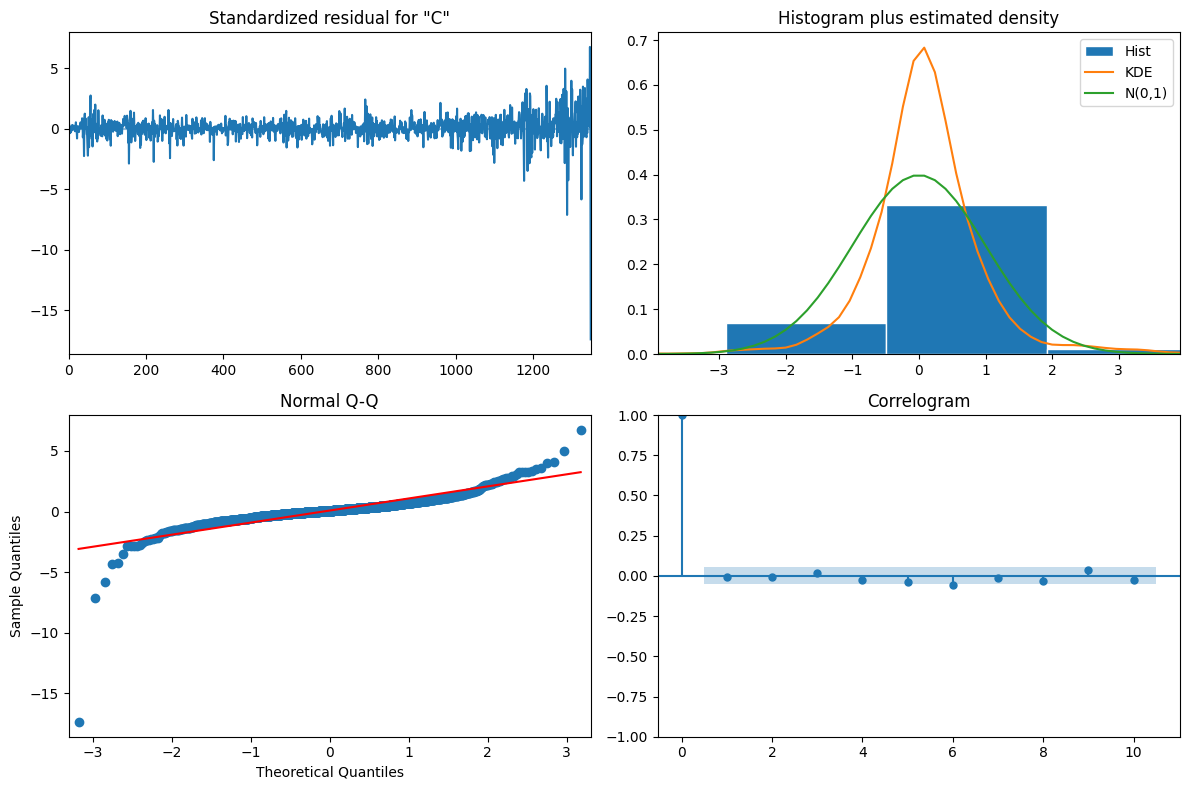

In [121]:
model_best = models[(0,1,2)]

model_best.plot_diagnostics(
    figsize=(12,8)
)

plt.tight_layout()
plt.show()

##Plot forecast pada data test

In [122]:
pred_test = model_best.forecast(
    steps=len(test)
)

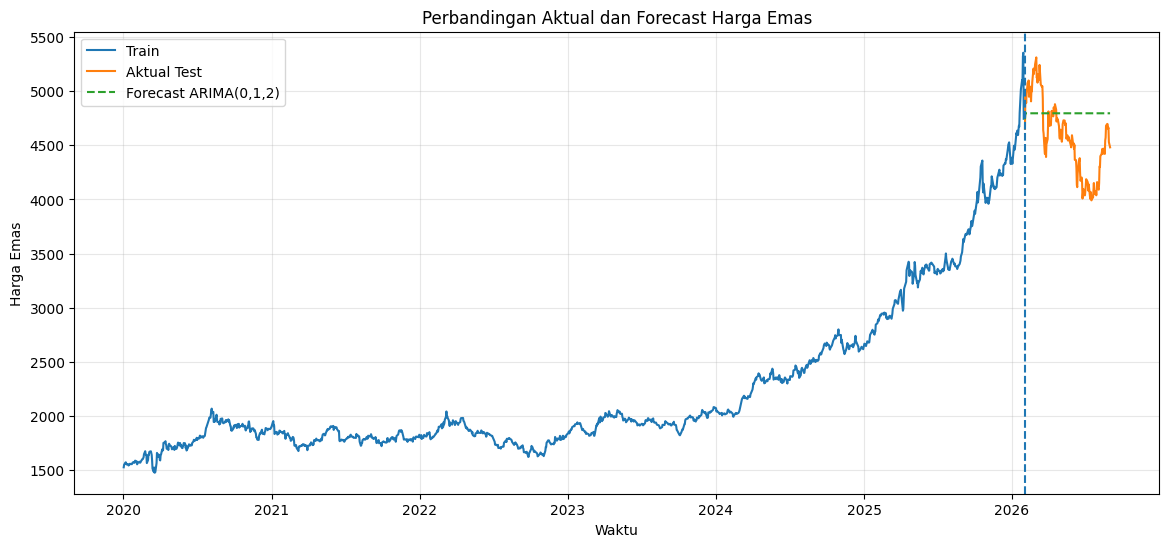

In [123]:
plt.figure(figsize=(14,6))

plt.plot(
    train['Date'],
    train['Close'],
    label='Train'
)

plt.plot(
    test['Date'],
    test['Close'],
    label='Aktual Test'
)

plt.plot(
    test['Date'],
    pred_test,
    linestyle='--',
    label='Forecast ARIMA(0,1,2)'
)

plt.axvline(
    x=test['Date'].iloc[0],
    linestyle='--'
)

plt.title(
    'Perbandingan Aktual dan Forecast Harga Emas'
)

plt.xlabel('Waktu')
plt.ylabel('Harga Emas')

plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [124]:
from statsmodels.tsa.arima.model import ARIMA

model_final = ARIMA(
    gold['Close'],
    order=(0,1,2)
).fit()

print(model_final.summary())

                               SARIMAX Results                                
Dep. Variable:                  Close   No. Observations:                 1501
Model:                 ARIMA(0, 1, 2)   Log Likelihood               -7691.463
Date:                Fri, 16 Oct 2026   AIC                          15388.927
Time:                        03:52:12   BIC                          15404.866
Sample:                             0   HQIC                         15394.865
                               - 1501                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ma.L1          0.0031      0.016      0.196      0.845      -0.028       0.035
ma.L2         -0.1049      0.010    -10.984      0.000      -0.124      -0.086
sigma2      1664.6586     17.640     94.370      0.0

In [125]:
forecast_final = model_final.get_forecast(
    steps=30
)

prediksi = forecast_final.predicted_mean
interval = forecast_final.conf_int(
    alpha=0.05
)

In [126]:
hasil_forecast = pd.DataFrame({
    'Forecast': prediksi,
    'Lower 95%': interval.iloc[:, 0],
    'Upper 95%': interval.iloc[:, 1]
})

hasil_forecast

,Forecast,Lower 95%,Upper 95%
1501,4495.855490,4415.888512,4575.822468
1502,4500.756852,4387.488308,4614.025397
1503,4500.756852,4366.632436,4634.881268
1504,4500.756852,4348.609047,4652.904658
1505,4500.756852,4332.505402,4669.008302
1506,4500.756852,4317.813839,4683.699866
1507,4500.756852,4304.217437,4697.296268
1508,4500.756852,4291.502611,4710.011094
1509,4500.756852,4279.517314,4721.996391
1510,4500.756852,4268.148750,4733.364954


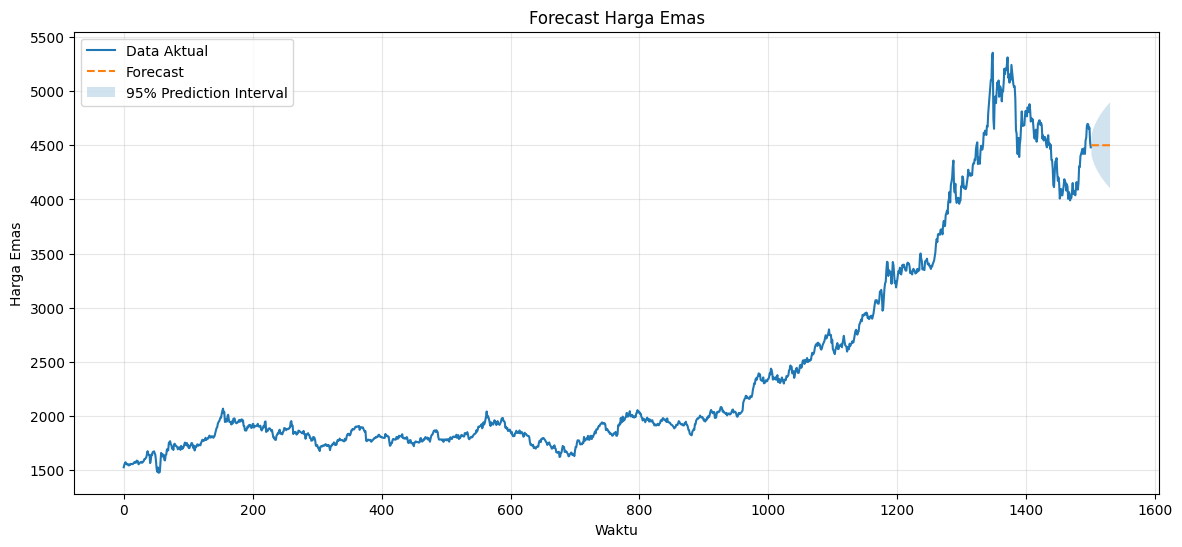

In [127]:
plt.figure(figsize=(14,6))

plt.plot(
    gold.index,
    gold['Close'],
    label='Data Aktual'
)

plt.plot(
    prediksi.index,
    prediksi,
    linestyle='--',
    label='Forecast'
)

plt.fill_between(
    prediksi.index,
    interval.iloc[:,0],
    interval.iloc[:,1],
    alpha=0.2,
    label='95% Prediction Interval'
)

plt.title('Forecast Harga Emas')
plt.xlabel('Waktu')
plt.ylabel('Harga Emas')
plt.legend()
plt.grid(alpha=0.3)

plt.show()

One Step Ahead

In [128]:
import numpy as np
import pandas as pd
import warnings

from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_absolute_error, mean_squared_error

In [129]:
def one_step_ahead_arima(train, test, order):

    # History menggunakan harga asli
    history = train['Close'].tolist()

    prediksi = []

    for actual_value in test['Close']:

        with warnings.catch_warnings():
            warnings.simplefilter("ignore")

            model = ARIMA(
                history,
                order=order
            ).fit()

        # Forecast 1 langkah ke depan
        yhat = model.forecast(
            steps=1
        )[0]

        prediksi.append(yhat)

        # Masukkan nilai aktual test ke history
        history.append(actual_value)

    return np.array(prediksi)

In [130]:
pred_arima_012 = one_step_ahead_arima(
    train,
    test,
    order=(0,1,2)
)

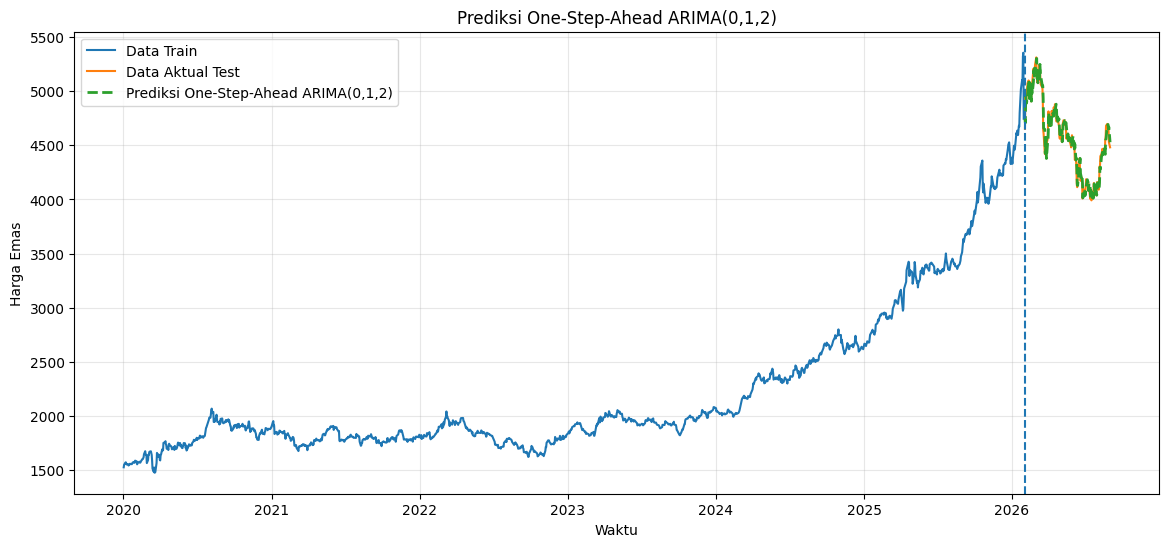

In [131]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14,6))

plt.plot(
    train['Date'],
    train['Close'],
    label='Data Train'
)

plt.plot(
    test['Date'],
    test['Close'],
    label='Data Aktual Test'
)

plt.plot(
    test['Date'],
    pred_arima_012,
    '--',
    linewidth=2,
    label='Prediksi One-Step-Ahead ARIMA(0,1,2)'
)

plt.axvline(
    x=test['Date'].iloc[0],
    linestyle='--'
)

plt.title(
    'Prediksi One-Step-Ahead ARIMA(0,1,2)'
)

plt.xlabel('Waktu')
plt.ylabel('Harga Emas')

plt.legend()
plt.grid(alpha=0.3)

plt.show()

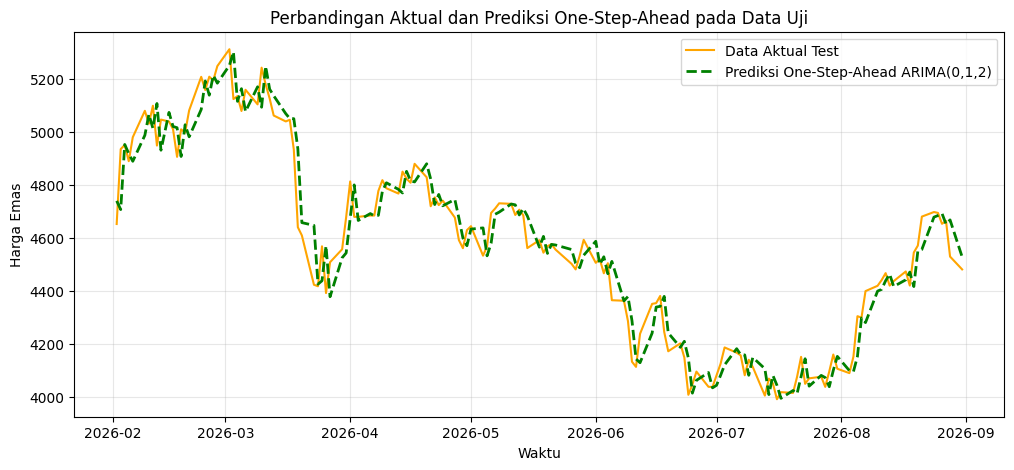

In [132]:
plt.figure(figsize=(12,5))

plt.plot(
    test['Date'],
    test['Close'],
    label='Data Aktual Test',
    color='orange'
)

plt.plot(
    test['Date'],
    pred_arima_012,
    '--',
    linewidth=2,
    label='Prediksi One-Step-Ahead ARIMA(0,1,2)',
    color='green'
)

plt.title('Perbandingan Aktual dan Prediksi One-Step-Ahead pada Data Uji')
plt.xlabel('Waktu')
plt.ylabel('Harga Emas')

plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [133]:
actual = test['Close'].values

mae_arima = mean_absolute_error(
    actual,
    pred_arima_012
)

rmse_arima = np.sqrt(
    mean_squared_error(
        actual,
        pred_arima_012
    )
)

mape_arima = np.mean(
    np.abs(
        (actual - pred_arima_012)
        / actual
    )
) * 100

print("MAE  :", mae_arima)
print("RMSE :", rmse_arima)
print("MAPE :", mape_arima, "%")

MAE  : 61.95206906773958
RMSE : 80.30585647585407
MAPE : 1.352852000053326 %


In [134]:
hasil_one_step = pd.DataFrame({
    'Date': test['Date'].values,
    'Aktual': actual,
    'Prediksi ARIMA': pred_arima_012,
    'Error': actual - pred_arima_012
})

hasil_one_step.head(10)

,Date,Aktual,Prediksi ARIMA,Error
0,2026-02-02,4652.6,4739.794189,-87.194189
1,2026-02-03,4935.0,4707.141308,227.858692
2,2026-02-04,4950.8,4952.548185,-1.748185
3,2026-02-05,4889.5,4918.289426,-28.789426
4,2026-02-06,4979.8,4889.093860,90.706140
5,2026-02-09,5079.4,4987.175912,92.224088
6,2026-02-10,5031.0,5065.859925,-34.859925
7,2026-02-11,5098.5,5013.372318,85.127682
8,2026-02-12,4948.4,5106.949882,-158.549882
9,2026-02-13,5046.3,4930.859815,115.440185


#LSTM

In [171]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

# Reproduksibilitas
tf.keras.backend.clear_session()
np.random.seed(47)
tf.random.set_seed(47)

# Pastikan data terurut berdasarkan waktu
train = train.sort_values('Date').reset_index(drop=True)
test = test.sort_values('Date').reset_index(drop=True)

train['Date'] = pd.to_datetime(train['Date'])
test['Date'] = pd.to_datetime(test['Date'])

print("Train:", len(train))
print("Test :", len(test))
print("Periode train:", train['Date'].min(), "-", train['Date'].max())
print("Periode test :", test['Date'].min(), "-", test['Date'].max())

# Pastikan tidak ada nilai Close yang hilang
assert train['Close'].notna().all(), "Ada NA pada Close train"
assert test['Close'].notna().all(), "Ada NA pada Close test"

# Scaling: scaler hanya dipelajari dari data train
scaler = MinMaxScaler(feature_range=(0, 1))

train_scaled = scaler.fit_transform(train[['Close']])
test_scaled = scaler.transform(test[['Close']])

print("Train scaled:", train_scaled.shape)
print("Test scaled :", test_scaled.shape)

Train: 1350
Test : 151
Periode train: 2020-01-02 00:00:00 - 2026-01-30 00:00:00
Periode test : 2026-02-02 00:00:00 - 2026-08-31 00:00:00
Train scaled: (1350, 1)
Test scaled : (151, 1)


In [172]:
np.random.seed(47)
tf.random.set_seed(47)

In [173]:
timesteps = 30

def create_sequences(data, timesteps=30):
    X, y = [], []

    for i in range(timesteps, len(data)):
        X.append(data[i-timesteps:i, 0])
        y.append(data[i, 0])

    return np.array(X), np.array(y)

X_train, y_train = create_sequences(
    train_scaled,
    timesteps
)

# Bentuk input menjadi (samples, timesteps, features)
X_train = X_train.reshape(
    X_train.shape[0],
    X_train.shape[1],
    1
)

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

X_train: (1320, 30, 1)
y_train: (1320,)


In [174]:
model_lstm = Sequential([
    LSTM(
        50,
        return_sequences=False,
        input_shape=(timesteps, 1)
    ),
    Dropout(0.2),
    Dense(1)
])

model_lstm.compile(
    optimizer='adam',
    loss='mean_squared_error'
)

model_lstm.summary()

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True
)

# Cukup satu kali fit
history = model_lstm.fit(
    X_train,
    y_train,
    epochs=100,
    batch_size=32,
    validation_split=0.1,
    shuffle=False,
    callbacks=[early_stop],
    verbose=1
)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 50)             │        10,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 50)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 10,451 (40.82 KB)

 Trainable params: 10,451 (40.82 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/100
38/38 ━━━━━━━━━━━━━━━━━━━━ 3s 14ms/step - loss: 0.0016 - val_loss: 0.0043
Epoch 2/100
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0061 - val_loss: 0.0128
Epoch 3/100
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0034 - val_loss: 8.1711e-04
Epoch 4/100
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 9.8242e-04 - val_loss: 0.0015
Epoch 5/100
38/38 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - loss: 3.8277e-04 - val_loss: 8.6342e-04
Epoch 6/100
38/38 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - loss: 4.9463e-04 - val_loss: 0.0011
Epoch 7/100
38/38 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 6.5006e-04 - val_loss: 0.0019
Epoch 8/100
38/38 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0011 - val_loss: 0.0012
Epoch 9/100
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 3.7497e-04 - val_loss: 7.9146e-04
Epoch 10/100
38/38 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 3.0073e-04 - val_loss: 7.5297e-04
Epoch 11/100
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 3.4458e-04 - val_loss: 7.4145e-04
Epoch 

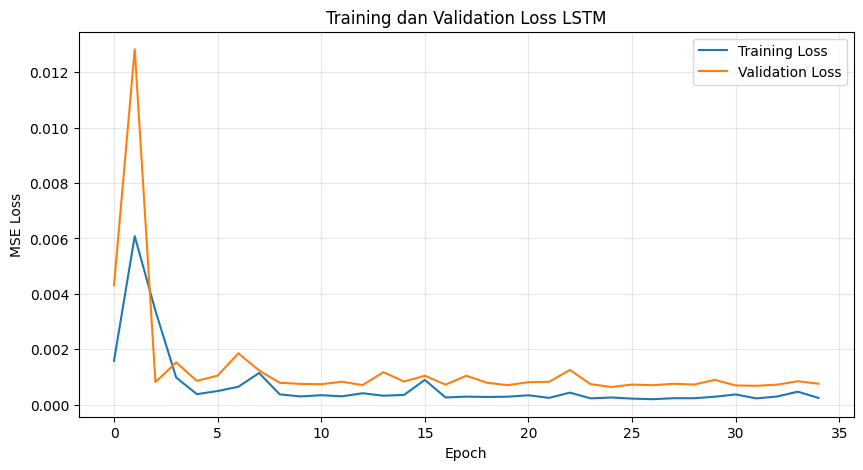

In [175]:
plt.figure(figsize=(10, 5))

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.title('Training dan Validation Loss LSTM')
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')

plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [176]:
# Awali history dengan seluruh data train
history_scaled = train_scaled[:, 0].tolist()

pred_lstm_scaled = []

for actual_scaled in test_scaled[:, 0]:

    # Ambil 30 observasi terakhir
    x_input = np.array(
        history_scaled[-timesteps:]
    ).reshape(1, timesteps, 1)

    # Prediksi satu langkah ke depan
    yhat = model_lstm.predict(
        x_input,
        verbose=0
    )[0, 0]

    pred_lstm_scaled.append(float(yhat))

    # Setelah prediksi dibuat, masukkan nilai aktual
    # untuk memprediksi observasi test berikutnya
    history_scaled.append(float(actual_scaled))

# Kembalikan ke skala harga emas
pred_lstm = scaler.inverse_transform(
    np.array(pred_lstm_scaled).reshape(-1, 1)
).flatten()

print("10 prediksi pertama:")
print(pred_lstm[:10])

10 prediksi pertama:
[5247.25663614 5173.11652875 5128.71496032 5093.71215946 5056.74747881
 5041.3419853  5052.72342997 5065.52463783 5092.34438956 5095.75052714]


In [177]:
actual = test['Close'].to_numpy()

mae_lstm = mean_absolute_error(actual, pred_lstm)

rmse_lstm = np.sqrt(
    mean_squared_error(actual, pred_lstm)
)

mape_lstm = np.mean(
    np.abs((actual - pred_lstm) / actual)
) * 100

print(f"MAE LSTM  : {mae_lstm:.4f}")
print(f"RMSE LSTM : {rmse_lstm:.4f}")
print(f"MAPE LSTM : {mape_lstm:.4f}%")

MAE LSTM  : 121.4909
RMSE LSTM : 161.3802
MAPE LSTM : 2.6706%


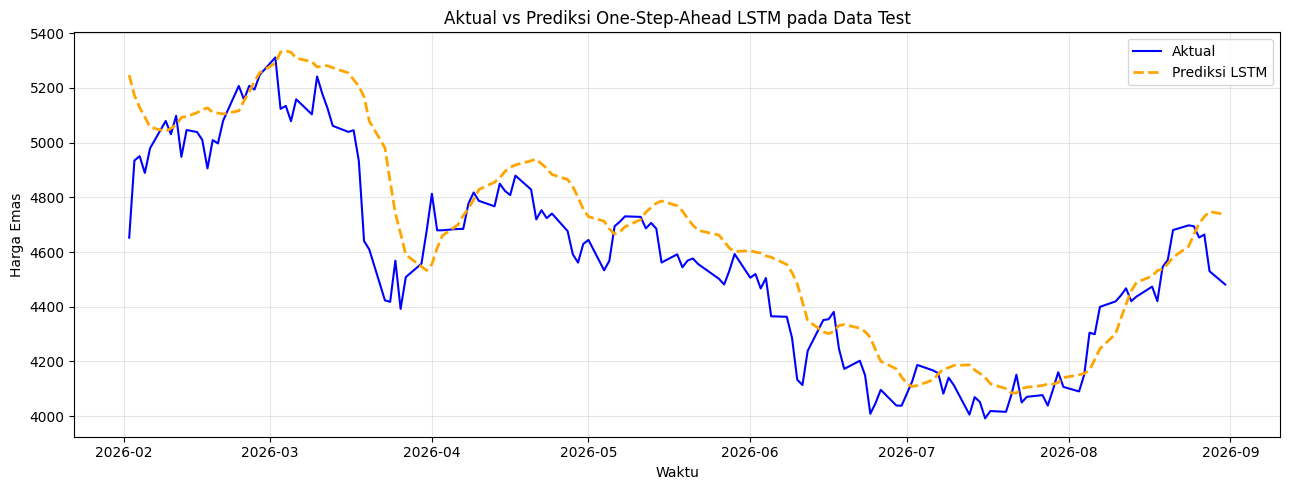

In [178]:
plt.figure(figsize=(13, 5))

plt.plot(
    test['Date'],
    actual,
    label='Aktual',
    color='blue'
)

plt.plot(
    test['Date'],
    pred_lstm,
    '--',
    linewidth=2,
    label='Prediksi LSTM',
    color='orange'
)

plt.title('Aktual vs Prediksi One-Step-Ahead LSTM pada Data Test')
plt.xlabel('Waktu')
plt.ylabel('Harga Emas')

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

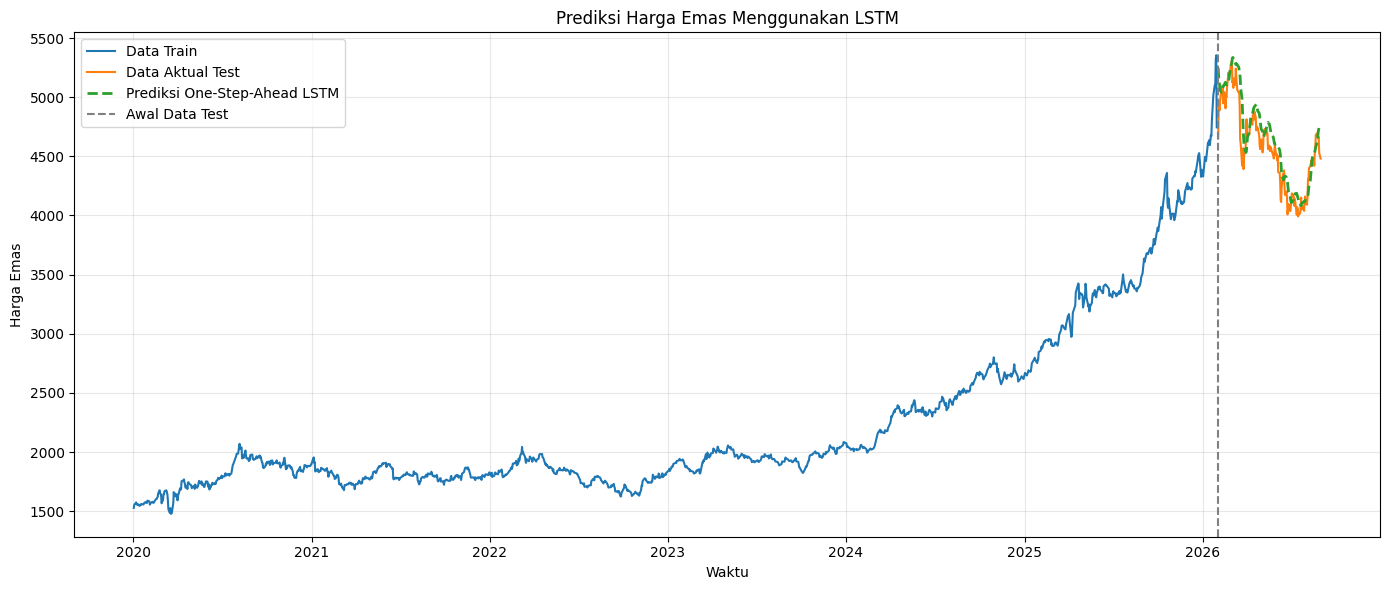

In [179]:
plt.figure(figsize=(14, 6))

plt.plot(
    train['Date'],
    train['Close'],
    label='Data Train'
)

plt.plot(
    test['Date'],
    test['Close'],
    label='Data Aktual Test'
)

plt.plot(
    test['Date'],
    pred_lstm,
    '--',
    linewidth=2,
    label='Prediksi One-Step-Ahead LSTM'
)

plt.axvline(
    x=test['Date'].iloc[0],
    linestyle='--',
    color='gray',
    label='Awal Data Test'
)

plt.title('Prediksi Harga Emas Menggunakan LSTM')
plt.xlabel('Waktu')
plt.ylabel('Harga Emas')

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [180]:
perbandingan = pd.DataFrame({
    'Model': ['ARIMA', 'LSTM'],
    'MAE': [mae_arima, mae_lstm],
    'RMSE': [rmse_arima, rmse_lstm],
    'MAPE (%)': [mape_arima, mape_lstm]
})

print(perbandingan.round(4))

   Model       MAE      RMSE  MAPE (%)
0  ARIMA   61.9521   80.3059    1.3529
1   LSTM  121.4909  161.3802    2.6706


##split

In [137]:
print("Train :", len(train))
print("Test  :", len(test))

print(
    "Periode train:",
    train['Date'].min(),
    "-",
    train['Date'].max()
)

print(
    "Periode test:",
    test['Date'].min(),
    "-",
    test['Date'].max()
)

Train : 1350
Test  : 151
Periode train: 2020-01-02 00:00:00 - 2026-01-30 00:00:00
Periode test: 2026-02-02 00:00:00 - 2026-08-31 00:00:00


Scaling

In [138]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler(
    feature_range=(0,1)
)

train_scaled = scaler.fit_transform(
    train[['Close']]
)

test_scaled = scaler.transform(
    test[['Close']]
)

In [139]:
print(train_scaled[:5])
print(test_scaled[:5])

[[0.01294849]
 [0.01921638]
 [0.02344657]
 [0.02486523]
 [0.0212283 ]]
[[0.81887591]
 [0.89171761]
 [0.89579303]
 [0.87998143]
 [0.90327323]]


tentukan widow/timesteps


In [140]:
timesteps = 30

In [141]:
def create_sequences(data, timesteps=30):

    X = []
    y = []

    for i in range(
        timesteps,
        len(data)
    ):

        X.append(
            data[
                i-timesteps:i,
                0
            ]
        )

        y.append(
            data[i,0]
        )

    return (
        np.array(X),
        np.array(y)
    )

In [142]:
X_train, y_train = create_sequences(
    train_scaled,
    timesteps
)

print("X_train shape :", X_train.shape)
print("y_train shape :", y_train.shape)

X_train shape : (1320, 30)
y_train shape : (1320,)


Ubah bentuk data untuk LSTM
LSTM memerlukan format:
\[
(samples,\ timesteps,\ features)
\]
Karena kita hanya memakai satu variabel Close:

In [143]:
X_train = X_train.reshape(
    X_train.shape[0],
    X_train.shape[1],
    1
)

print(
    "Shape X_train:",
    X_train.shape
)

Shape X_train: (1320, 30, 1)


Membuat model LSTM

In [144]:
model_lstm = Sequential([

    LSTM(
        50,
        return_sequences=False,
        input_shape=(timesteps, 1)
    ),

    Dropout(0.2),

    Dense(1)
])

/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [145]:
model_lstm.compile(
    optimizer='adam',
    loss='mean_squared_error'
)

model_lstm.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 50)             │        10,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 50)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 10,451 (40.82 KB)

 Trainable params: 10,451 (40.82 KB)

 Non-trainable params: 0 (0.00 B)

##Early stopping


Supaya training berhenti ketika validation loss tidak membaik:

In [146]:
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True
)

In [147]:
history = model_lstm.fit(
    X_train,
    y_train,

    epochs=100,
    batch_size=32,

    validation_split=0.1,

    shuffle=False,

    callbacks=[
        early_stop
    ],

    verbose=1
)

Epoch 1/100
38/38 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - loss: 0.0010 - val_loss: 0.0040
Epoch 2/100
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0027 - val_loss: 0.0020
Epoch 3/100
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0039 - val_loss: 0.0018
Epoch 4/100
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0032 - val_loss: 8.0705e-04
Epoch 5/100
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 7.8309e-04 - val_loss: 7.2768e-04
Epoch 6/100
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 4.4338e-04 - val_loss: 7.8893e-04
Epoch 7/100
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 4.4269e-04 - val_loss: 7.0631e-04
Epoch 8/100
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 3.1852e-04 - val_loss: 6.9312e-04
Epoch 9/100
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 2.9232e-04 - val_loss: 8.4952e-04
Epoch 10/100
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 3.2527e-04 - val_loss: 9.1173e-04
Epoch 11/100
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 3.8613e-04 - val_loss: 7.3344

Training LSTM

In [148]:
history = model_lstm.fit(
    X_train,
    y_train,

    epochs=100,
    batch_size=32,

    validation_split=0.1,

    shuffle=False,

    callbacks=[
        early_stop
    ],

    verbose=1
)

Epoch 1/100
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 3.8268e-04 - val_loss: 0.0015
Epoch 2/100
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 3.9570e-04 - val_loss: 6.9463e-04
Epoch 3/100
38/38 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 2.8420e-04 - val_loss: 7.3118e-04
Epoch 4/100
38/38 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - loss: 3.4114e-04 - val_loss: 0.0011
Epoch 5/100
38/38 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - loss: 3.2607e-04 - val_loss: 7.8335e-04
Epoch 6/100
38/38 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 5.0055e-04 - val_loss: 7.2278e-04
Epoch 7/100
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 3.6097e-04 - val_loss: 7.1771e-04
Epoch 8/100
38/38 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 2.7056e-04 - val_loss: 0.0010
Epoch 9/100
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 3.5575e-04 - val_loss: 8.4269e-04
Epoch 10/100
38/38 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 5.1579e-04 - val_loss: 8.8879e-04


Plot training loss dan validation loss

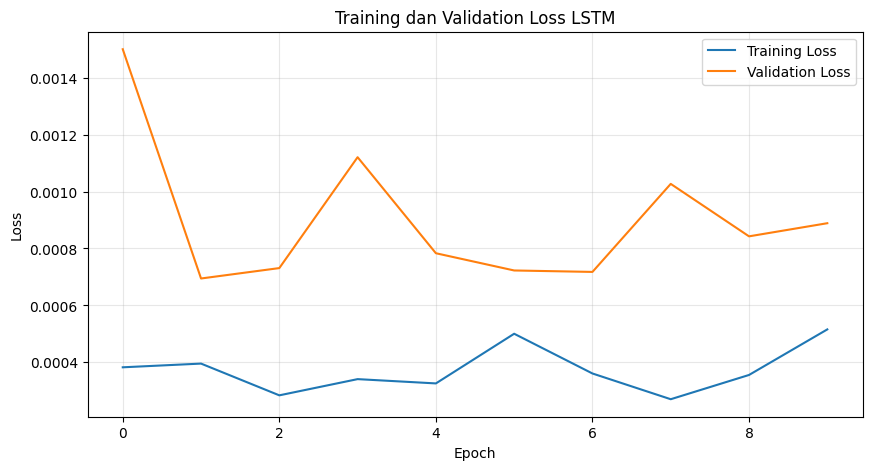

In [149]:
plt.figure(figsize=(10,5))

plt.plot(
    history.history['loss'],
    label='Training Loss'
)

plt.plot(
    history.history['val_loss'],
    label='Validation Loss'
)

plt.title(
    'Training dan Validation Loss LSTM'
)

plt.xlabel('Epoch')
plt.ylabel('Loss')

plt.legend()
plt.grid(alpha=0.3)

plt.show()

Forecast data test

In [164]:
history_scaled = list(
    train_scaled[:,0]
)

pred_lstm_scaled = []

for i in range(len(test)):

    # Ambil 30 observasi terakhir
    x_input = np.array(
        history_scaled[-timesteps:]
    )

    x_input = x_input.reshape(
        1,
        timesteps,
        1
    )

    # Prediksi satu langkah
    yhat = model_lstm.predict(
        x_input,
        verbose=0
    )[0,0]

    pred_lstm_scaled.append(
        yhat
    )

    # Untuk forecast berikutnya,
    # masukkan hasil prediksi sebelumnya
    history_scaled.append(actual_scaled)

Kembalikan prediksi ke skala harga asli

In [165]:
pred_lstm = scaler.inverse_transform(
    np.array(
        pred_lstm_scaled
    ).reshape(-1,1)
).flatten()

In [166]:
print(pred_lstm[:10])

[5067.806  4995.178  4908.988  4819.1816 4733.2593 4655.9263 4589.804
 4535.692  4493.3945 4461.9463]


Hitung MAE, RMSE, dan MAPE LSTM

In [168]:
actual = test['Close'].values

mae_lstm = mean_absolute_error(
    actual,
    pred_lstm
)

rmse_lstm = np.sqrt(
    mean_squared_error(
        actual,
        pred_lstm
    )
)

mape_lstm = np.mean(
    np.abs(
        (actual - pred_lstm)
        / actual
    )
) * 100

print("MAE LSTM  :", mae_lstm)
print("RMSE LSTM :", rmse_lstm)
print("MAPE LSTM :", mape_lstm, "%")

MAE LSTM  : 302.8012131363824
RMSE LSTM : 367.75103385299883
MAPE LSTM : 6.508090732946208 %


Plot aktual vs prediksi LSTM

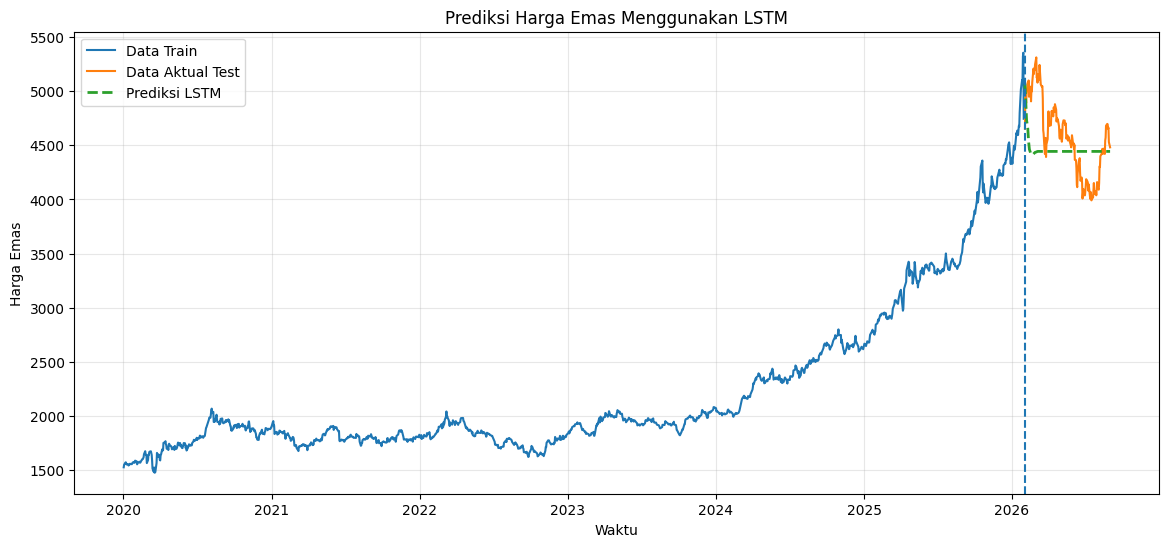

In [169]:
plt.figure(figsize=(14,6))

plt.plot(
    train['Date'],
    train['Close'],
    label='Data Train'
)

plt.plot(
    test['Date'],
    test['Close'],
    label='Data Aktual Test'
)

plt.plot(
    test['Date'],
    pred_lstm,
    '--',
    linewidth=2,
    label='Prediksi LSTM'
)

plt.axvline(
    x=test['Date'].iloc[0],
    linestyle='--'
)

plt.title(
    'Prediksi Harga Emas Menggunakan LSTM'
)

plt.xlabel('Waktu')
plt.ylabel('Harga Emas')

plt.legend()
plt.grid(alpha=0.3)

plt.show()

Plot khusus periode test

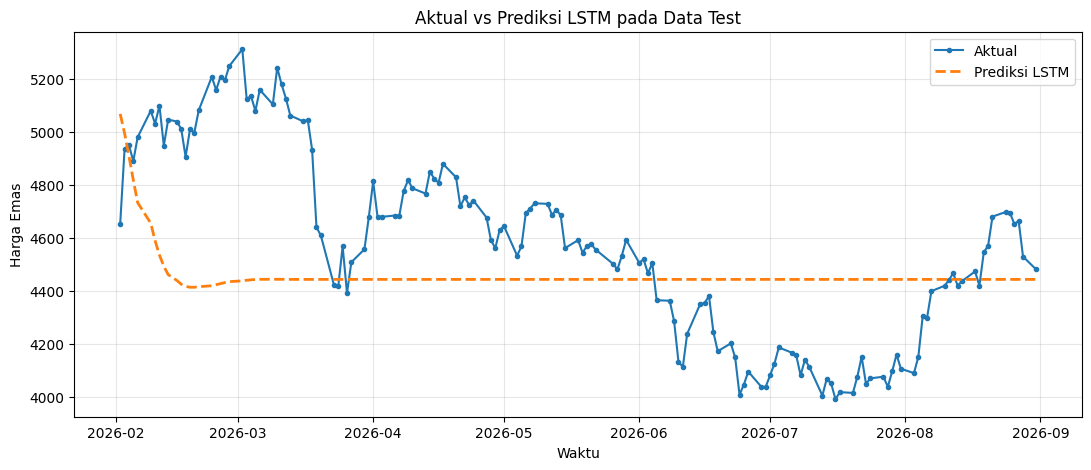

In [170]:
plt.figure(figsize=(13,5))

plt.plot(
    test['Date'],
    test['Close'],
    marker='o',
    markersize=3,
    label='Aktual'
)

plt.plot(
    test['Date'],
    pred_lstm,
    '--',
    linewidth=2,
    label='Prediksi LSTM'
)

plt.title(
    'Aktual vs Prediksi LSTM pada Data Test'
)

plt.xlabel('Waktu')
plt.ylabel('Harga Emas')

plt.legend()
plt.grid(alpha=0.3)

plt.show()

Bandingkan ARIMA dengan LSTM

In [156]:
mae_arima
rmse_arima
mape_arima

np.float64(1.352852000053326)

In [157]:
perbandingan = pd.DataFrame({
    'Model': [
        'ARIMA',
        'LSTM'
    ],

    'MAE': [
        mae_arima,
        mae_lstm
    ],

    'RMSE': [
        rmse_arima,
        rmse_lstm
    ],

    'MAPE (%)': [
        mape_arima,
        mape_lstm
    ]
})

perbandingan.round(4)

,Model,MAE,RMSE,MAPE (%)
0,ARIMA,61.9521,80.3059,1.3529
1,LSTM,284.9009,334.1749,6.4947


one step ahead

In [158]:
history_scaled = list(
    train_scaled[:, 0]
)

pred_lstm_scaled = []

In [159]:
for actual_scaled in test_scaled[:, 0]:

    # Ambil 30 observasi terakhir
    x_input = np.array(
        history_scaled[-timesteps:]
    )

    # Bentuk sesuai input LSTM:
    # (samples, timesteps, features)
    x_input = x_input.reshape(
        1,
        timesteps,
        1
    )

    # Prediksi 1 langkah ke depan
    yhat = model_lstm.predict(
        x_input,
        verbose=0
    )[0, 0]

    pred_lstm_scaled.append(
        yhat
    )

    # Setelah aktual tersedia,
    # masukkan aktual ke history
    history_scaled.append(
        actual_scaled
    )

kembalikan ke skala harga emas

In [160]:
pred_lstm = scaler.inverse_transform(
    np.array(
        pred_lstm_scaled
    ).reshape(-1, 1)
).flatten()

In [161]:
print(pred_lstm[:10])

[5067.806  5020.5073 5003.339  4987.5474 4964.162  4955.567  4965.0464
 4971.138  4988.5464 4984.81  ]


In [162]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error
)

actual = test['Close'].values

mae_lstm = mean_absolute_error(
    actual,
    pred_lstm
)

rmse_lstm = np.sqrt(
    mean_squared_error(
        actual,
        pred_lstm
    )
)

mape_lstm = np.mean(
    np.abs(
        (actual - pred_lstm)
        / actual
    )
) * 100

print("MAE LSTM  :", mae_lstm)
print("RMSE LSTM :", rmse_lstm)
print("MAPE LSTM :", mape_lstm, "%")

MAE LSTM  : 105.9361249223924
RMSE LSTM : 137.35326847124819
MAPE LSTM : 2.3239625543190994 %


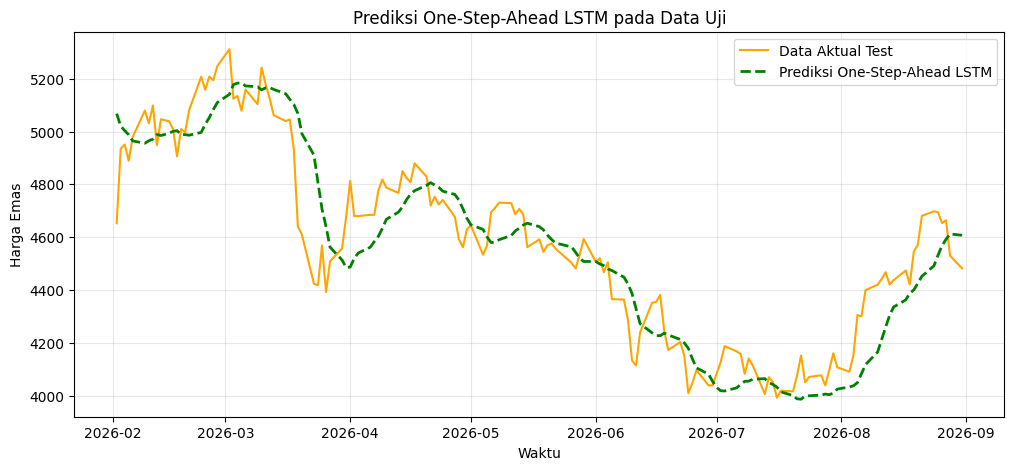

In [163]:
plt.figure(figsize=(12,5))

plt.plot(
    test['Date'],
    test['Close'],
    label='Data Aktual Test',
    color='orange'
)

plt.plot(
    test['Date'],
    pred_lstm,
    '--',
    linewidth=2,
    label='Prediksi One-Step-Ahead LSTM',
    color='green'
)

plt.title(
    'Prediksi One-Step-Ahead LSTM pada Data Uji'
)

plt.xlabel('Waktu')
plt.ylabel('Harga Emas')

plt.legend()
plt.grid(alpha=0.3)

plt.show()